In [92]:
import numpy as np
import pandas as pd
df = pd.read_csv("../dataprep/clean_segmentation_data_customer.csv")

In [93]:
df_encoded = pd.get_dummies(df, columns=["Country"], dtype=int)

In [94]:
df_encoded.head()

,Unnamed: 0,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,MissingCustomer,Transaction_Total,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,False,15.30,...,0,0,0,0,0,0,0,0,1,0
1,1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,False,22.00,...,0,0,0,0,0,0,0,0,1,0
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0


In [95]:
numeric_cols = df_encoded.select_dtypes(include="number").columns.tolist()
numeric_cols

['Unnamed: 0',
 'InvoiceNo',
 'Quantity',
 'UnitPrice',
 'CustomerID',
 'Transaction_Total',
 'Country_Australia',
 'Country_Austria',
 'Country_Bahrain',
 'Country_Belgium',
 'Country_Brazil',
 'Country_Canada',
 'Country_Channel Islands',
 'Country_Cyprus',
 'Country_Czech Republic',
 'Country_Denmark',
 'Country_EIRE',
 'Country_European Community',
 'Country_Finland',
 'Country_France',
 'Country_Germany',
 'Country_Greece',
 'Country_Iceland',
 'Country_Israel',
 'Country_Italy',
 'Country_Japan',
 'Country_Lebanon',
 'Country_Lithuania',
 'Country_Malta',
 'Country_Netherlands',
 'Country_Norway',
 'Country_Poland',
 'Country_Portugal',
 'Country_RSA',
 'Country_Saudi Arabia',
 'Country_Singapore',
 'Country_Spain',
 'Country_Sweden',
 'Country_Switzerland',
 'Country_USA',
 'Country_United Arab Emirates',
 'Country_United Kingdom',
 'Country_Unspecified']

In [96]:
numeric_cols.remove('CustomerID')
numeric_cols.remove('Unnamed: 0')
numeric_cols.remove('InvoiceNo')

In [97]:
customer_df = (df_encoded.groupby("CustomerID")[numeric_cols].sum().reset_index())

In [98]:
customer_df

,CustomerID,Quantity,UnitPrice,Transaction_Total,Country_Australia,Country_Austria,Country_Bahrain,Country_Belgium,Country_Brazil,Country_Canada,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,12346.0,74215,1.04,77183.60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,12347.0,2458,481.21,4310.00,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,12348.0,2341,178.71,1797.24,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,12349.0,631,605.10,1757.55,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12350.0,197,65.30,334.40,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,45,47.65,180.60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,10,0
4334,18281.0,54,39.36,80.82,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,7,0
4335,18282.0,103,62.39,178.05,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,12,0
4336,18283.0,1357,1174.33,2045.53,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,721,0


/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

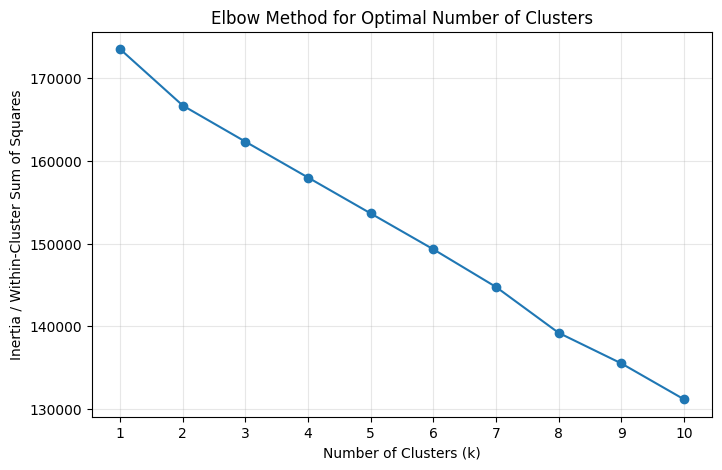

In [99]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

X = customer_df.drop(columns="CustomerID")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [100]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X = customer_df.drop(columns="CustomerID")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_pca.py:606: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work

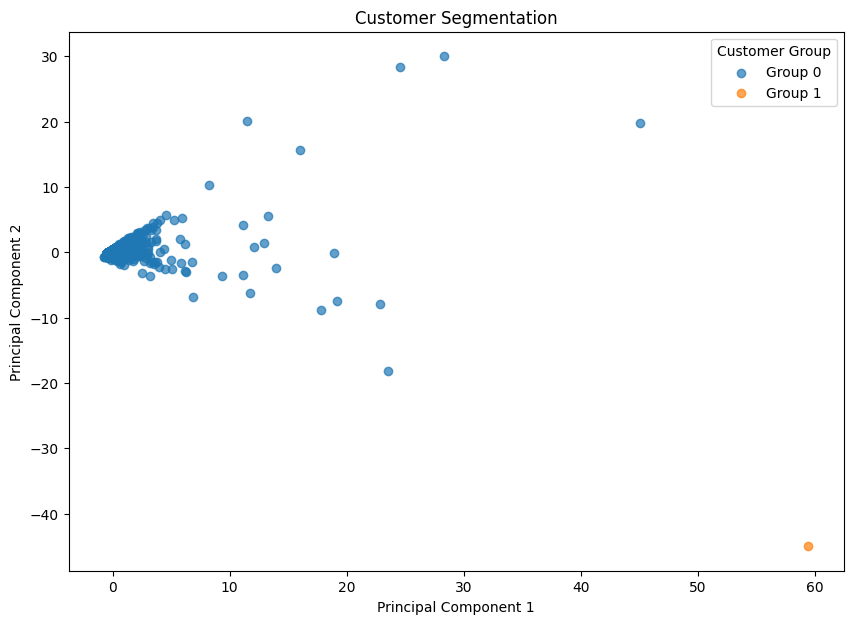

In [101]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")


plt.show()

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

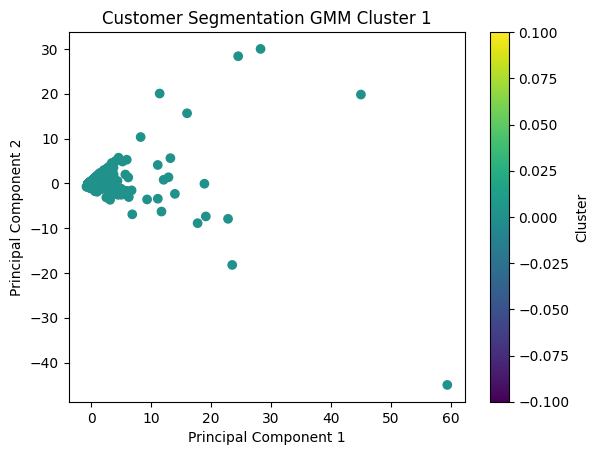

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

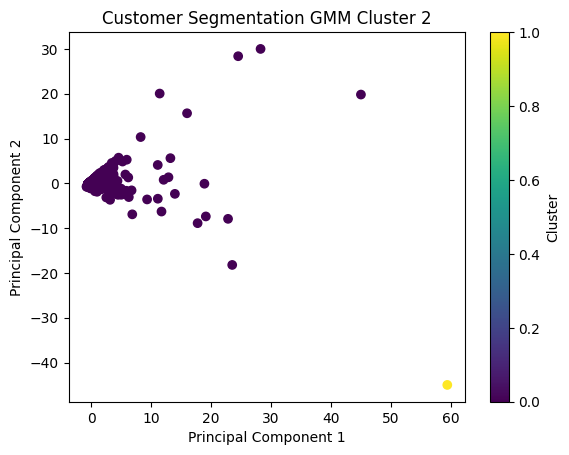

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

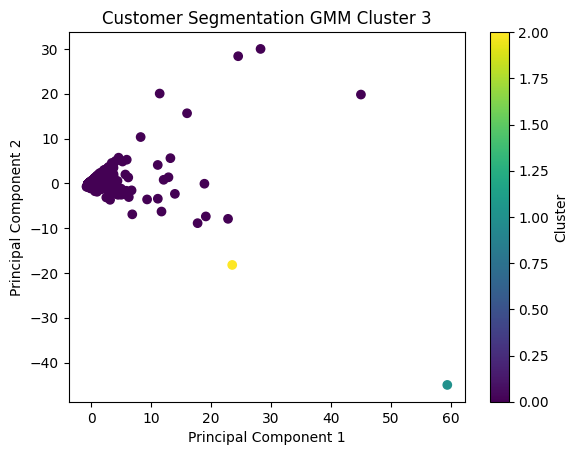

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

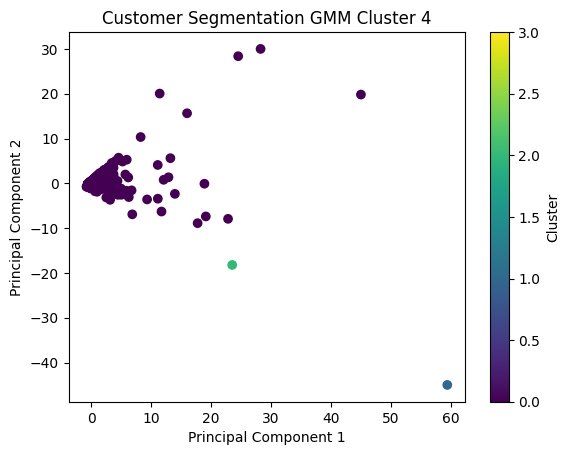

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

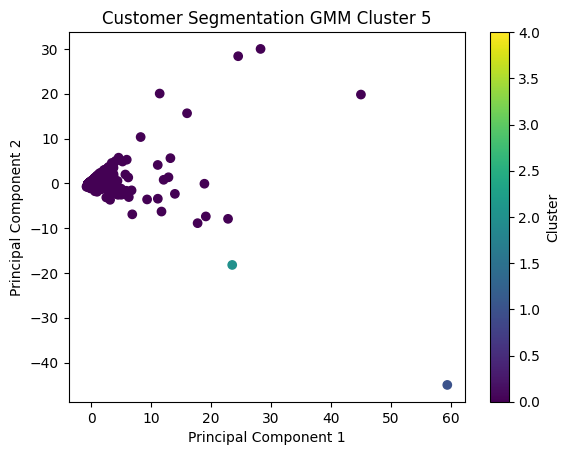

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

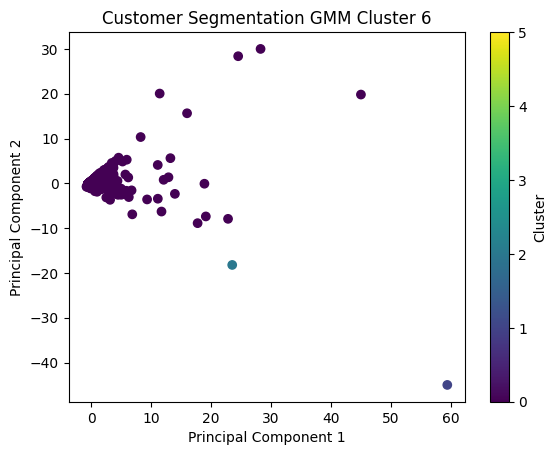

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

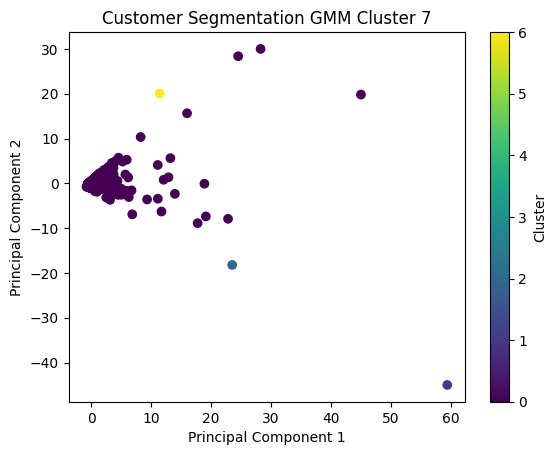

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

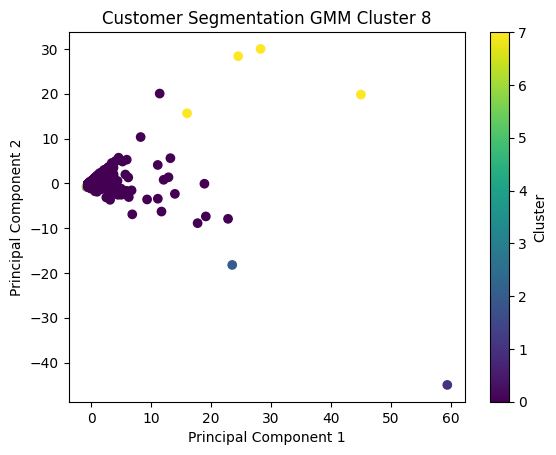

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

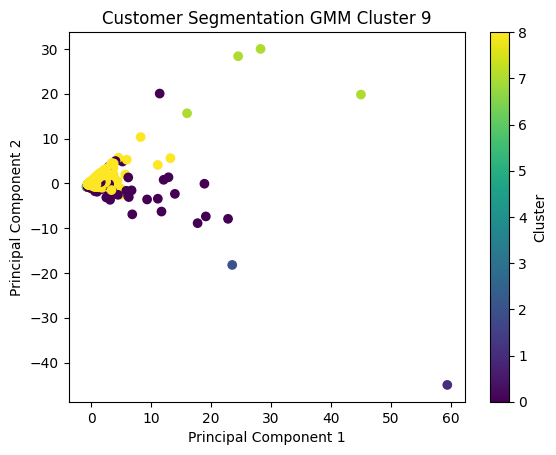

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

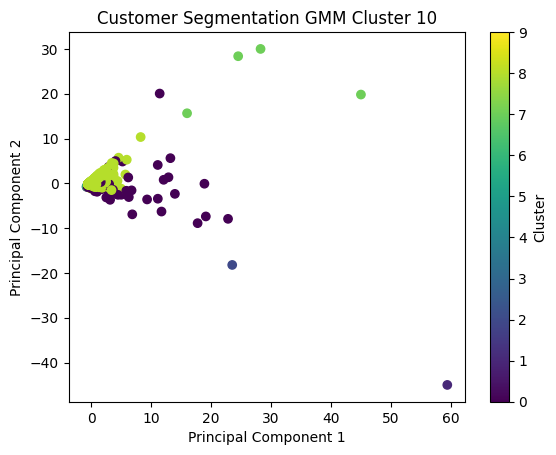

In [102]:
from sklearn.mixture import GaussianMixture

for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
    )
    
    labels = gmm.fit_predict(X_scaled)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")

    plt.show()

In [103]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = (df.groupby("CustomerID").agg( monetary=("Transaction_Total", "sum"), frequency=("InvoiceNo", "nunique"), total_quantity=("Quantity", "sum"), unique_products=("StockCode", "nunique"), last_purchase=("InvoiceDate", "max") ).reset_index() )

customer_df.head()

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00


In [104]:
customer_df['avg_purchase_val'] = customer_df['monetary'] / customer_df['frequency']
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase,avg_purchase_val
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,77183.600000
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00,615.714286
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00,449.310000
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00,1757.550000
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,334.400000
...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,2011-03-07 09:52:00,180.600000
4334,18281.0,80.82,1,54,7,2011-06-12 10:53:00,80.820000
4335,18282.0,178.05,2,103,12,2011-12-02 11:43:00,89.025000
4336,18283.0,2045.53,16,1357,263,2011-12-06 12:02:00,127.845625


In [105]:
customer_df['recency'] = (reference_date - customer_df['last_purchase']).dt.days
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase,avg_purchase_val,recency
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,77183.600000,326
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00,615.714286,2
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00,449.310000,75
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00,1757.550000,19
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,334.400000,310
...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,2011-03-07 09:52:00,180.600000,278
4334,18281.0,80.82,1,54,7,2011-06-12 10:53:00,80.820000,181
4335,18282.0,178.05,2,103,12,2011-12-02 11:43:00,89.025000,8
4336,18283.0,2045.53,16,1357,263,2011-12-06 12:02:00,127.845625,4


In [106]:
customer_df = customer_df.drop(columns=["last_purchase"])

In [107]:
customer_df.describe()

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency
count,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,2048.688081,4.272015,1187.644537,61.501153,417.645735,92.536422
std,1721.808492,8985.230220,7.697998,5043.619654,85.366768,1796.511343,100.014169
min,12346.000000,3.750000,1.000000,1.000000,1.000000,3.450000,1.000000
25%,13813.250000,306.482500,1.000000,159.000000,16.000000,177.867083,18.000000
50%,15299.500000,668.570000,2.000000,378.000000,35.000000,291.940000,51.000000
75%,16778.750000,1660.597500,5.000000,989.750000,77.000000,428.280625,142.000000
max,18287.000000,280206.020000,209.000000,196915.000000,1787.000000,84236.250000,374.000000


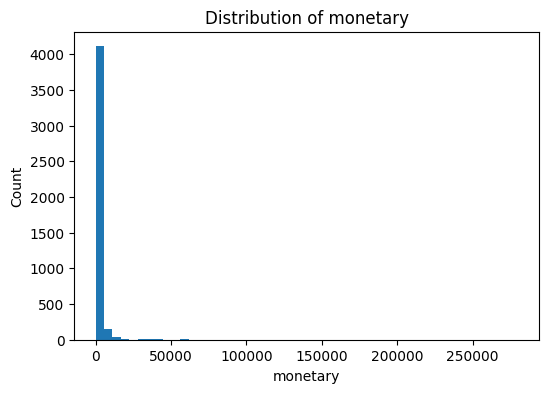

In [108]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(customer_df['monetary'], bins=50)
plt.title(f"Distribution of monetary")
plt.xlabel('monetary')
plt.ylabel("Count")
plt.show()

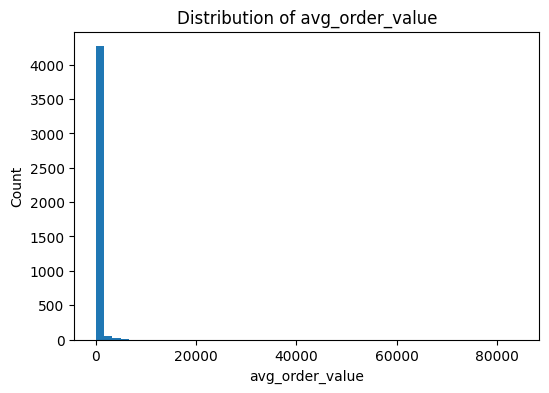

In [109]:
plt.figure(figsize=(6, 4))
plt.hist(customer_df['avg_purchase_val'], bins=50)
plt.title(f"Distribution of avg_order_value")
plt.xlabel('avg_order_value')
plt.ylabel("Count")
plt.show()

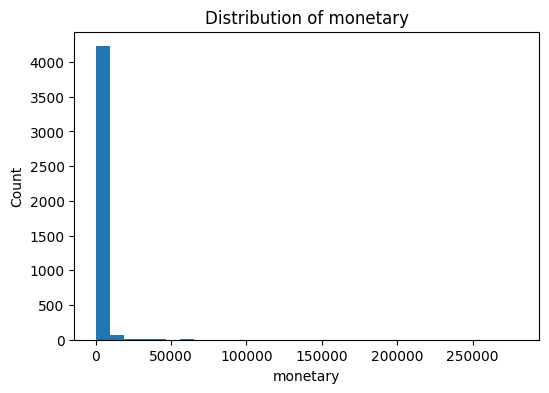

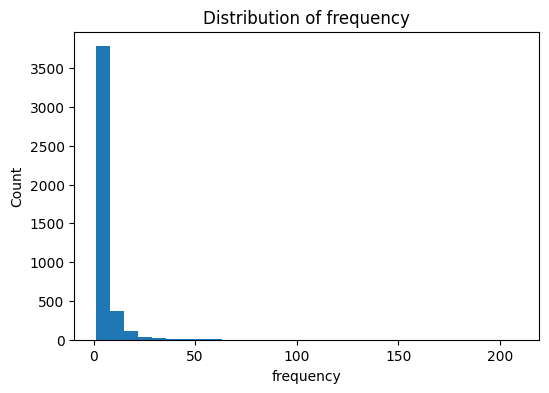

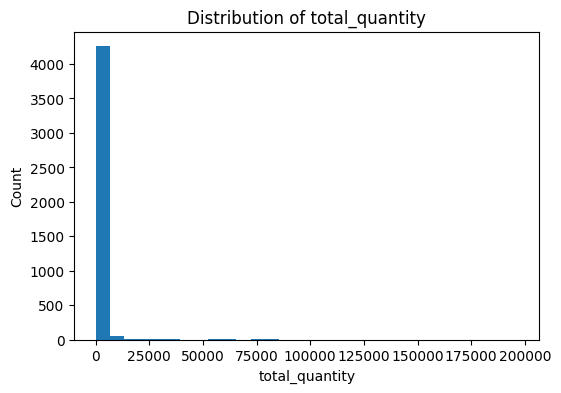

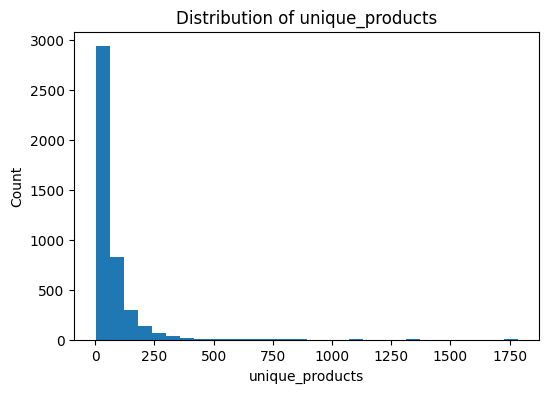

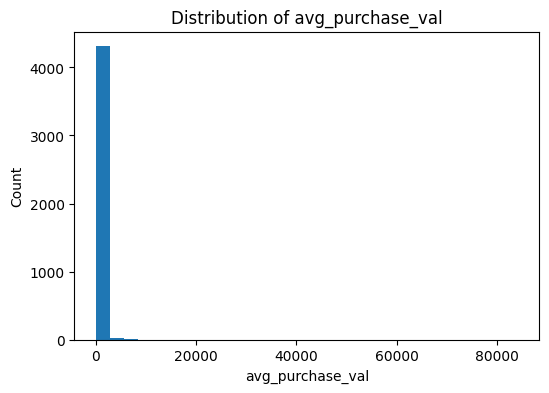

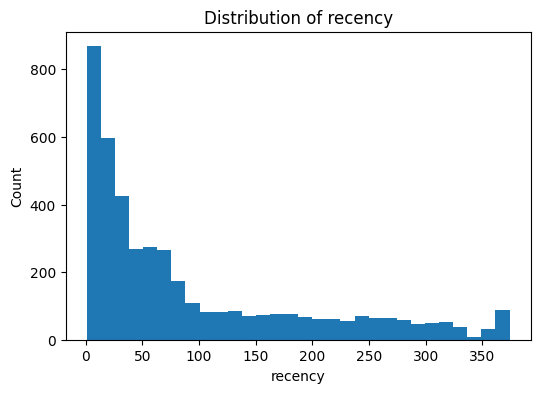

In [110]:
import matplotlib.pyplot as plt

features = ["monetary", "frequency", "total_quantity", "unique_products", "avg_purchase_val", 'recency']
for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(customer_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [111]:
import numpy as np
features = ["monetary", "frequency", "total_quantity", "unique_products", "avg_purchase_val"]


for col in features:
    customer_df[f"log_{col}"] = np.log1p(customer_df[col])

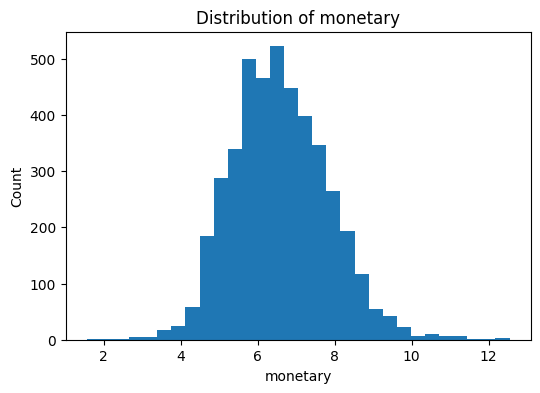

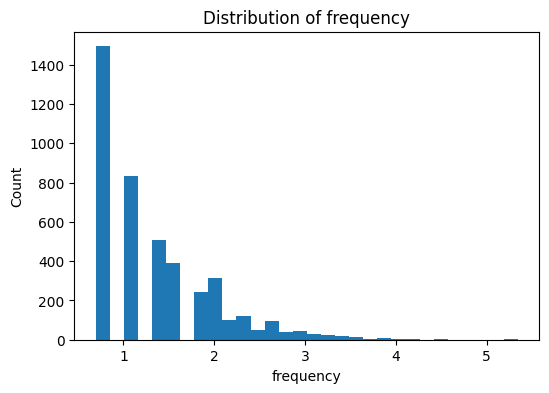

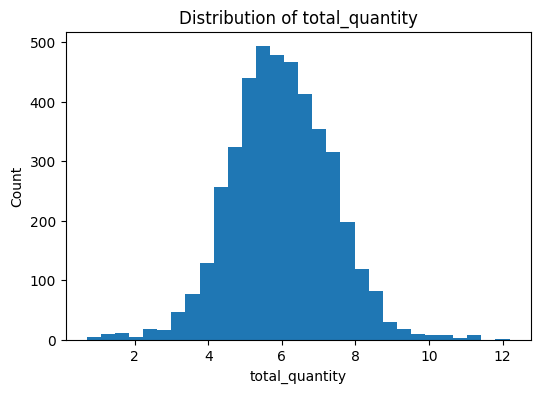

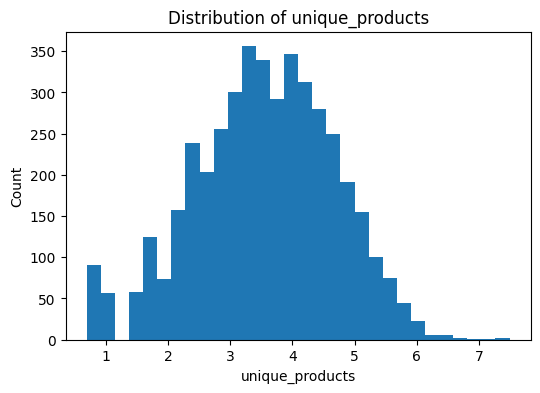

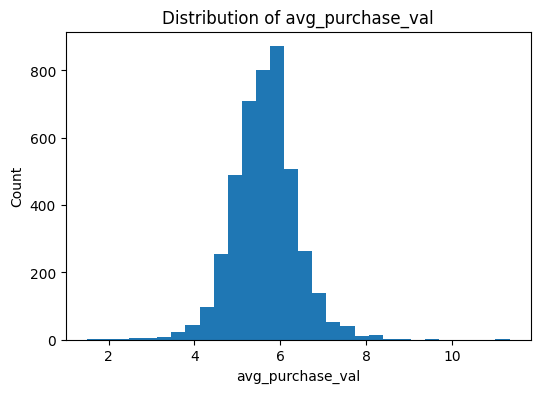

In [112]:
for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(customer_df[f"log_{col}"], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [113]:
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val
0,12346.0,77183.60,1,74215,1,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955
1,12347.0,4310.00,7,2458,103,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406
2,12348.0,1797.24,4,2341,22,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936
3,12349.0,1757.55,1,631,73,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245
4,12350.0,334.40,1,197,17,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324
...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,180.600000,278,5.201806,0.693147,3.828641,2.397895,5.201806
4334,18281.0,80.82,1,54,7,80.820000,181,4.404522,0.693147,4.007333,2.079442,4.404522
4335,18282.0,178.05,2,103,12,89.025000,8,5.187665,1.098612,4.644391,2.564949,4.500087
4336,18283.0,2045.53,16,1357,263,127.845625,4,7.623901,2.833213,7.213768,5.575949,4.858615


In [114]:
from sklearn.preprocessing import StandardScaler

model_features = ["log_monetary", "log_frequency", "log_total_quantity", "log_unique_products", "log_avg_purchase_val", "recency" ]
scaler = StandardScaler()
X = customer_df[model_features]
X_scaled = scaler.fit_transform(X)
# X_scaled = customer_df[model_features]

X_scaled.shape

(4338, 6)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

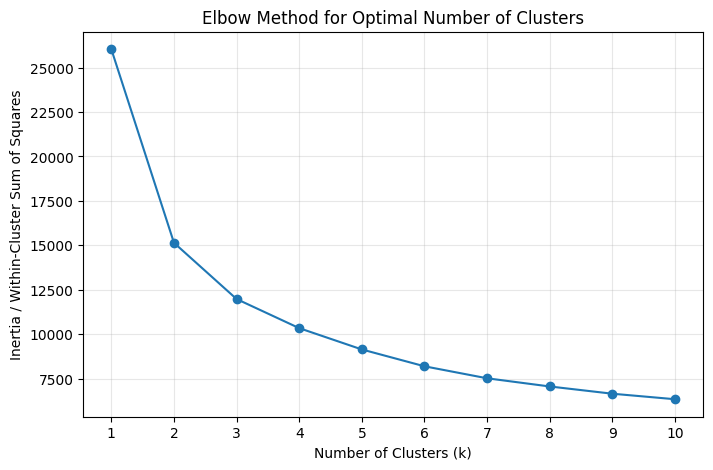

In [115]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [116]:
results

[{'k': 2, 'silhouette_score': np.float64(0.35087972449004934)},
 {'k': 3, 'silhouette_score': np.float64(0.27233856936839324)},
 {'k': 4, 'silhouette_score': np.float64(0.2739923858800578)},
 {'k': 5, 'silhouette_score': np.float64(0.24079500780616786)},
 {'k': 6, 'silhouette_score': np.float64(0.24415073069456075)},
 {'k': 7, 'silhouette_score': np.float64(0.23076296777819227)},
 {'k': 8, 'silhouette_score': np.float64(0.22364332616920457)},
 {'k': 9, 'silhouette_score': np.float64(0.21659909598091084)},
 {'k': 10, 'silhouette_score': np.float64(0.21664041376811313)}]

In [117]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

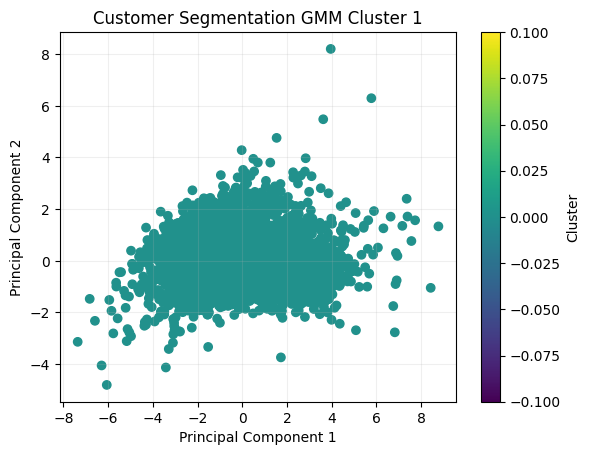

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

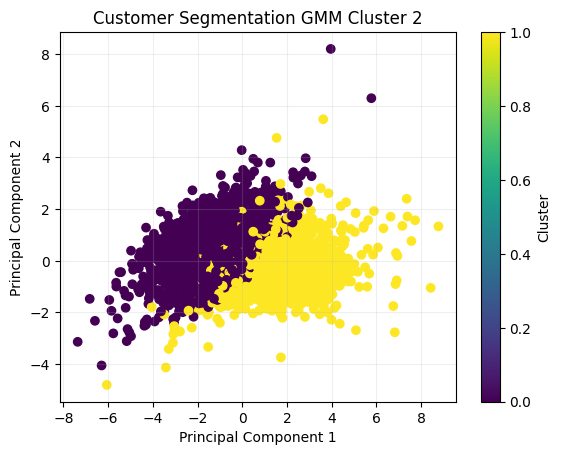

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

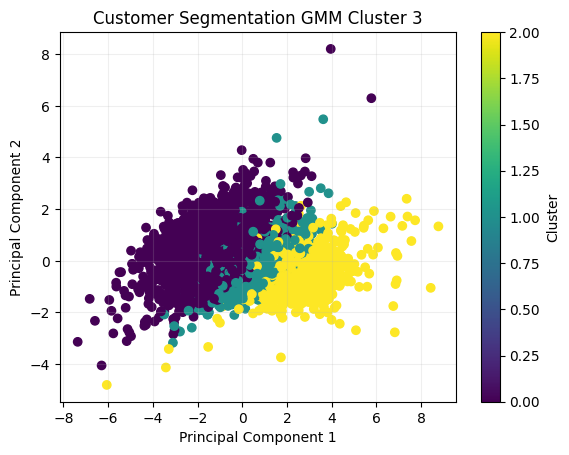

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

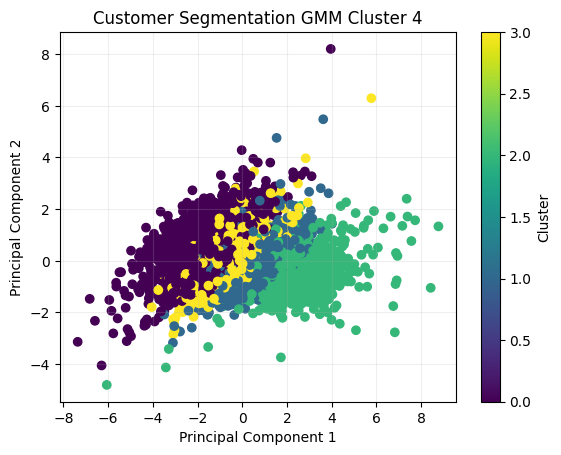

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

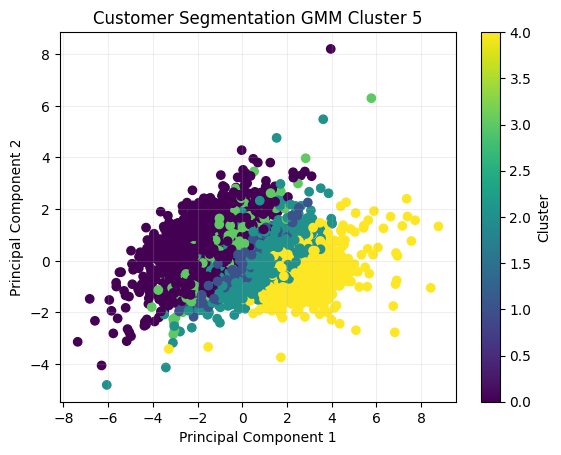

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

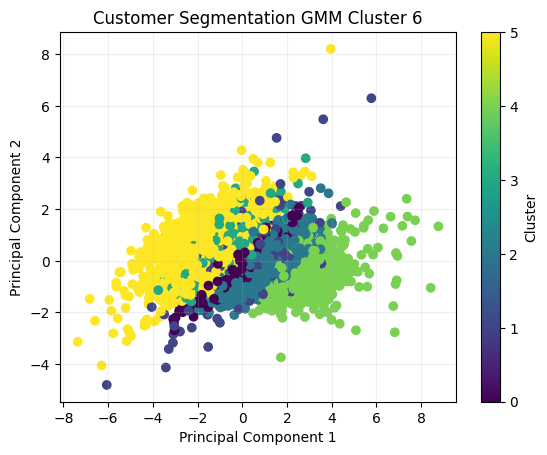

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

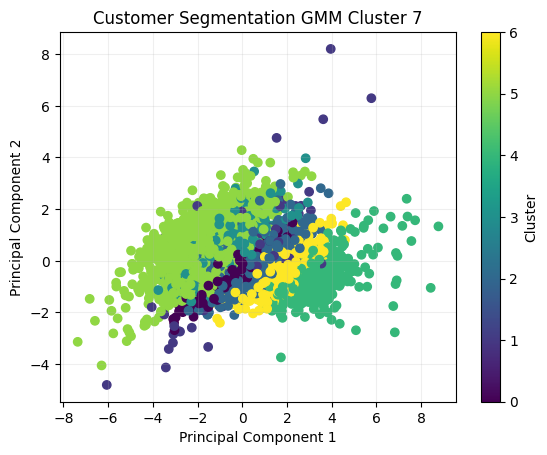

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

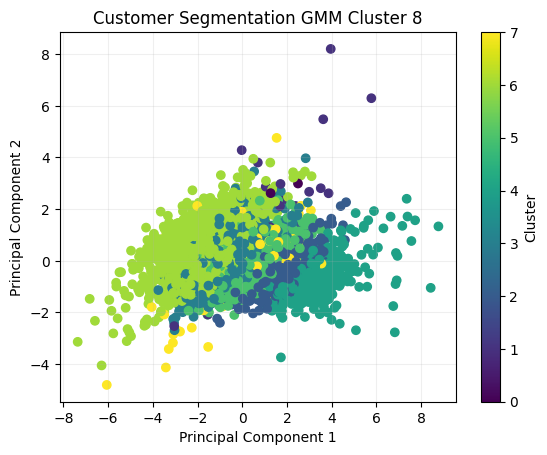

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

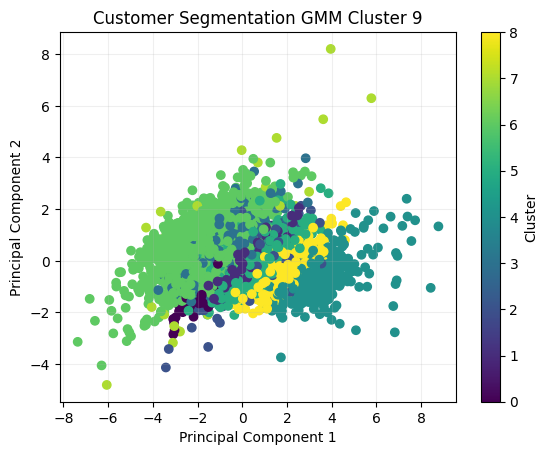

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

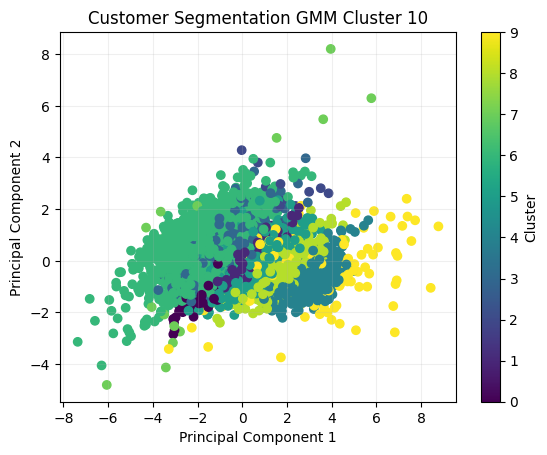

In [118]:
from sklearn.mixture import GaussianMixture

for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
    )
    
    labels = gmm.fit_predict(X_scaled)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [119]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


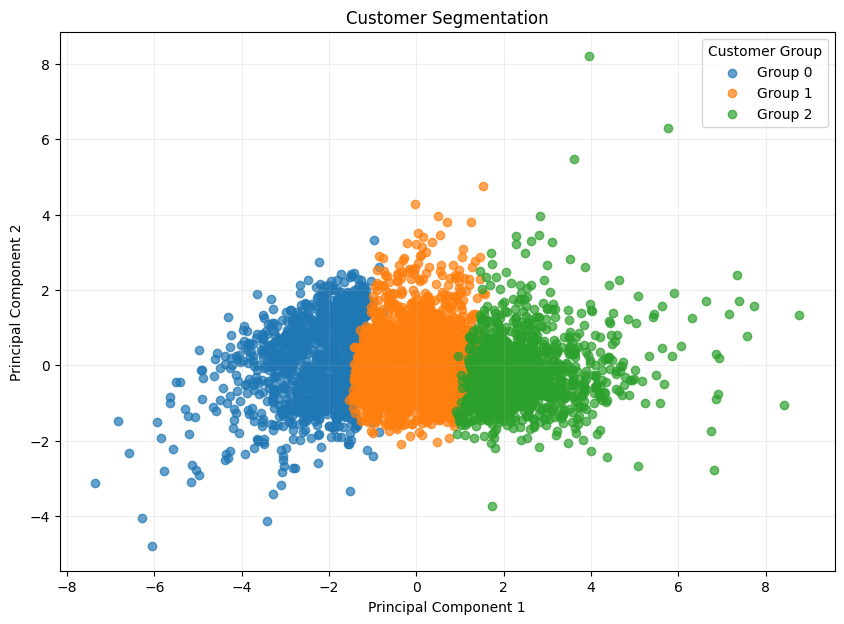

In [120]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [121]:
customer_df[model_features].corr()

,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,recency
log_monetary,1.000000,0.808119,0.921667,0.692399,0.708863,-0.434169
log_frequency,0.808119,1.000000,0.752504,0.622730,0.164300,-0.472760
log_total_quantity,0.921667,0.752504,1.000000,0.701705,0.642217,-0.452703
log_unique_products,0.692399,0.622730,0.701705,1.000000,0.403010,-0.418400
log_avg_purchase_val,0.708863,0.164300,0.642217,0.403010,1.000000,-0.138638
recency,-0.434169,-0.472760,-0.452703,-0.418400,-0.138638,1.000000


In [124]:
from sklearn.preprocessing import StandardScaler

model_features = ["log_frequency", "log_unique_products", "log_avg_purchase_val", "recency" ]
scaler = StandardScaler()
X = customer_df[model_features]
X_scaled = scaler.fit_transform(X)
# X_scaled = customer_df[model_features]

X_scaled.shape

(4338, 4)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

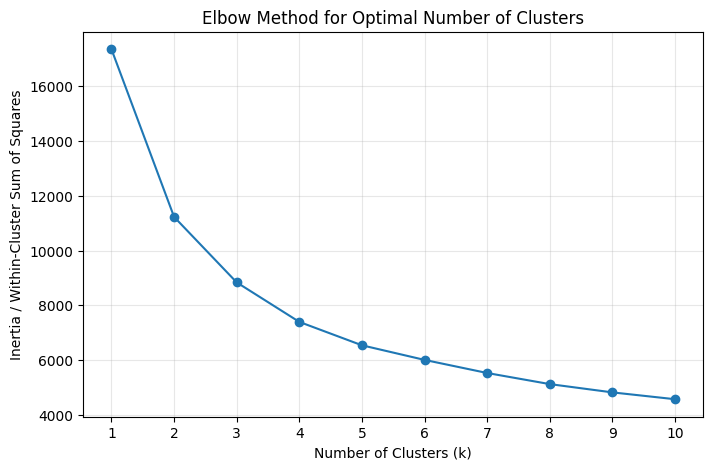

In [125]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

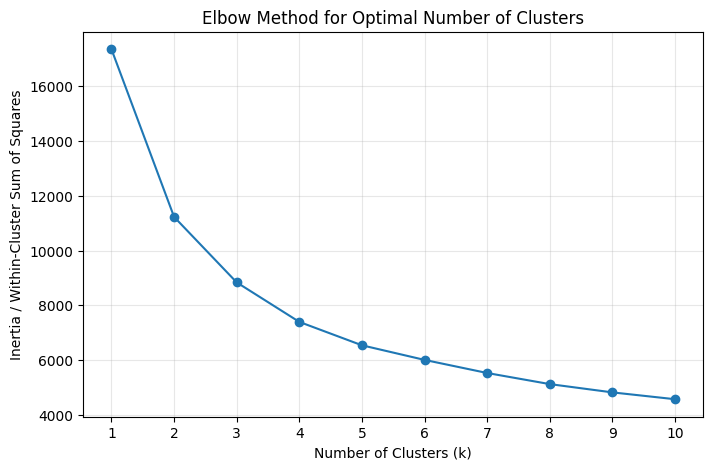

In [126]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [127]:
results

[{'k': 2, 'silhouette_score': np.float64(0.31015871895355135)},
 {'k': 3, 'silhouette_score': np.float64(0.2850039810724538)},
 {'k': 4, 'silhouette_score': np.float64(0.26314985212400066)},
 {'k': 5, 'silhouette_score': np.float64(0.24428434650781977)},
 {'k': 6, 'silhouette_score': np.float64(0.2358414087524427)},
 {'k': 7, 'silhouette_score': np.float64(0.23321248819291643)},
 {'k': 8, 'silhouette_score': np.float64(0.21596791292438206)},
 {'k': 9, 'silhouette_score': np.float64(0.21186066804534134)},
 {'k': 10, 'silhouette_score': np.float64(0.21797955505066394)}]

In [128]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

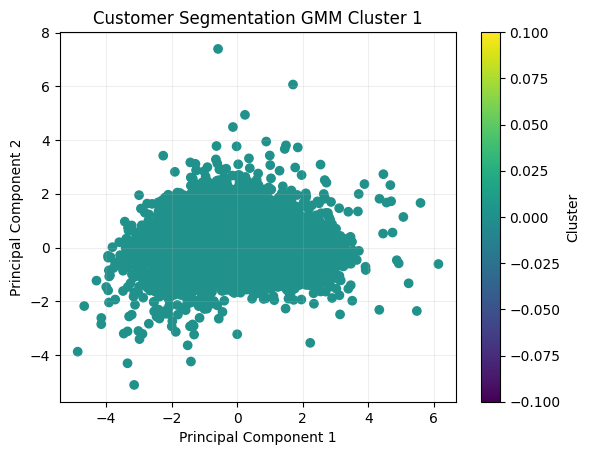

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

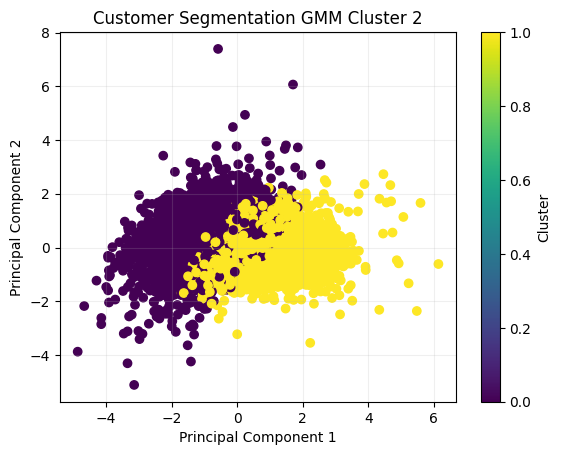

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

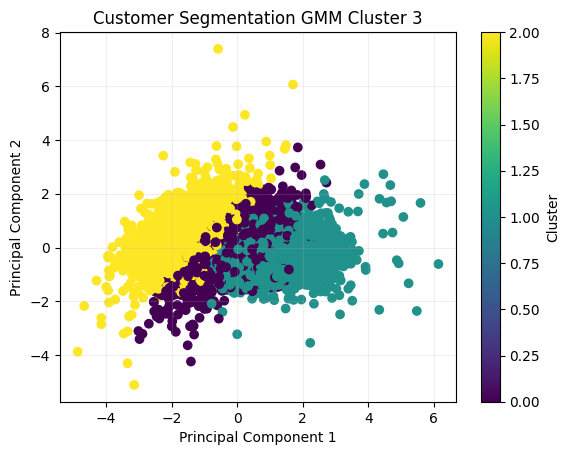

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

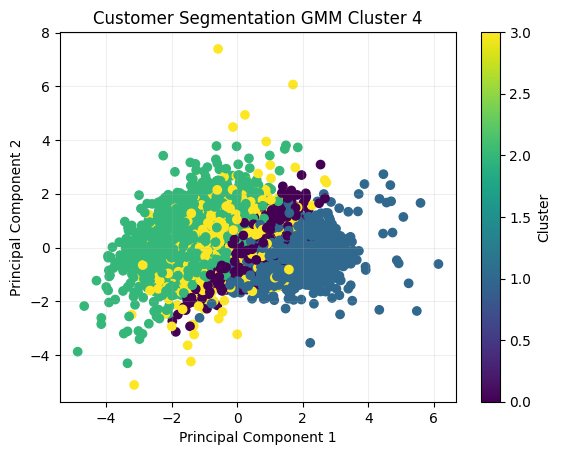

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

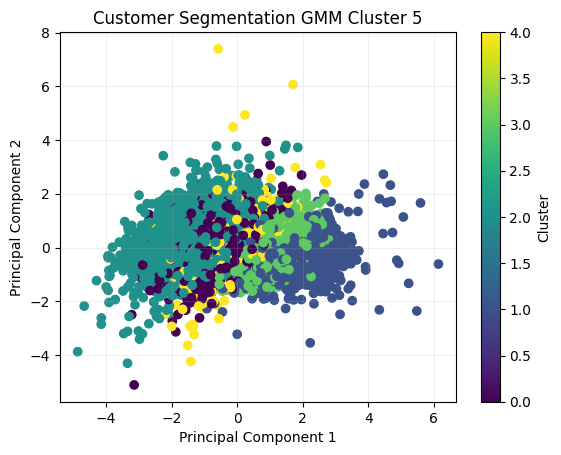

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

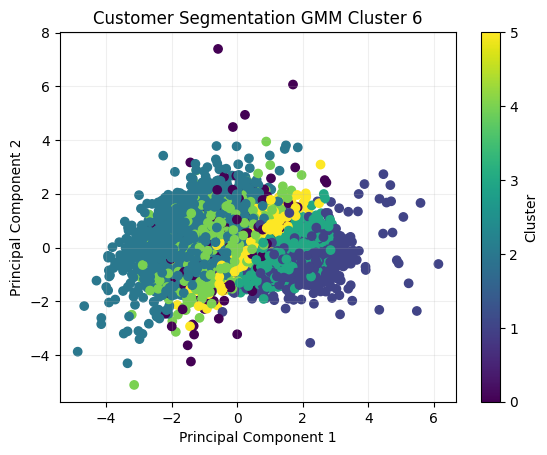

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

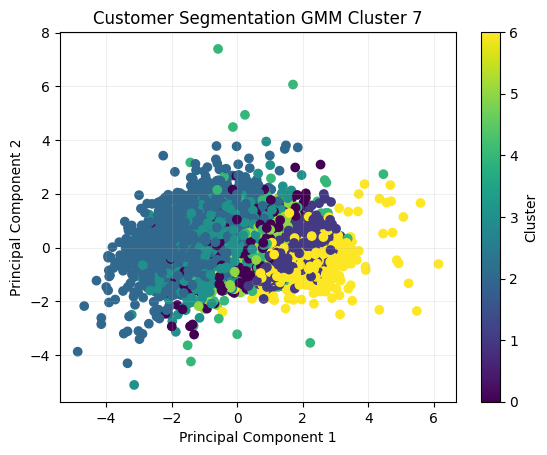

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

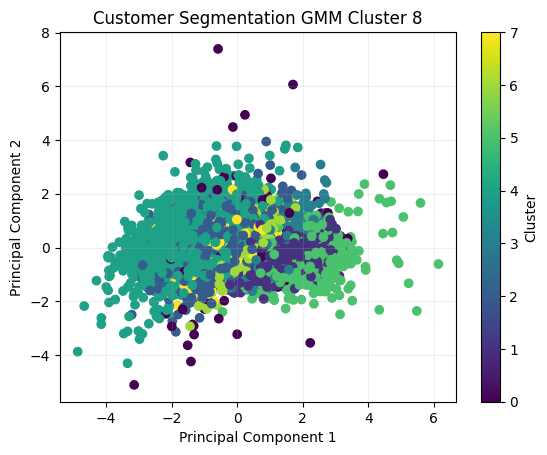

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

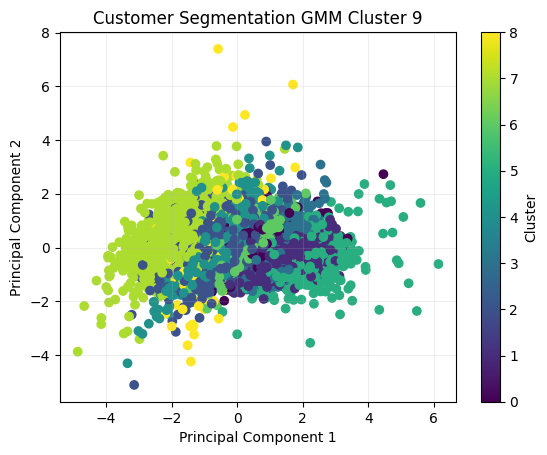

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

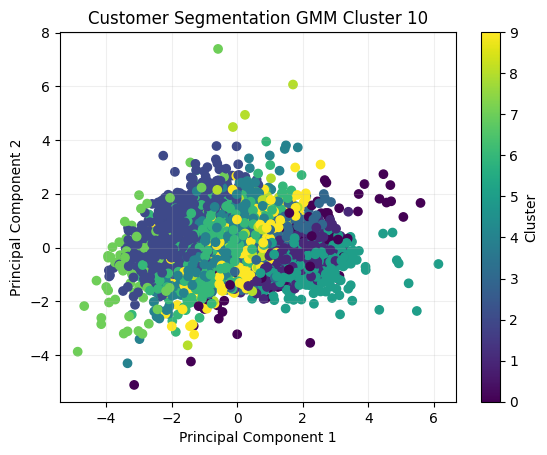

In [129]:
from sklearn.mixture import GaussianMixture
result = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        covariance_type='full'
    )
    
    labels = gmm.fit_predict(X_scaled)
    
    result.append({"K-val": k, "AIC": gmm.aic(X_scaled), "BIC": gmm.bic(X_scaled), "Log-likelihood": gmm.score(X_scaled)})
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [130]:
result

[{'K-val': 1,
  'AIC': np.float64(45069.42592739552),
  'BIC': np.float64(45158.67828907493),
  'Log-likelihood': np.float64(-5.191496764337888)},
 {'K-val': 2,
  'AIC': np.float64(40075.1191467551),
  'BIC': np.float64(40259.99903880532),
  'Log-likelihood': np.float64(-4.612392709400081)},
 {'K-val': 3,
  'AIC': np.float64(38951.34035734798),
  'BIC': np.float64(39231.847779769),
  'Log-likelihood': np.float64(-4.4794076022761615)},
 {'K-val': 4,
  'AIC': np.float64(22572.996741123352),
  'BIC': np.float64(22949.131693915173),
  'Log-likelihood': np.float64(-2.588173898239206)},
 {'K-val': 5,
  'AIC': np.float64(14110.310072067932),
  'BIC': np.float64(14582.072555230558),
  'Log-likelihood': np.float64(-1.609302682349923)},
 {'K-val': 6,
  'AIC': np.float64(13681.540036352679),
  'BIC': np.float64(14248.930049886105),
  'Log-likelihood': np.float64(-1.5564246238304147)},
 {'K-val': 7,
  'AIC': np.float64(8982.723170073972),
  'BIC': np.float64(9645.7407139782),
  'Log-likelihood': n

In [131]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


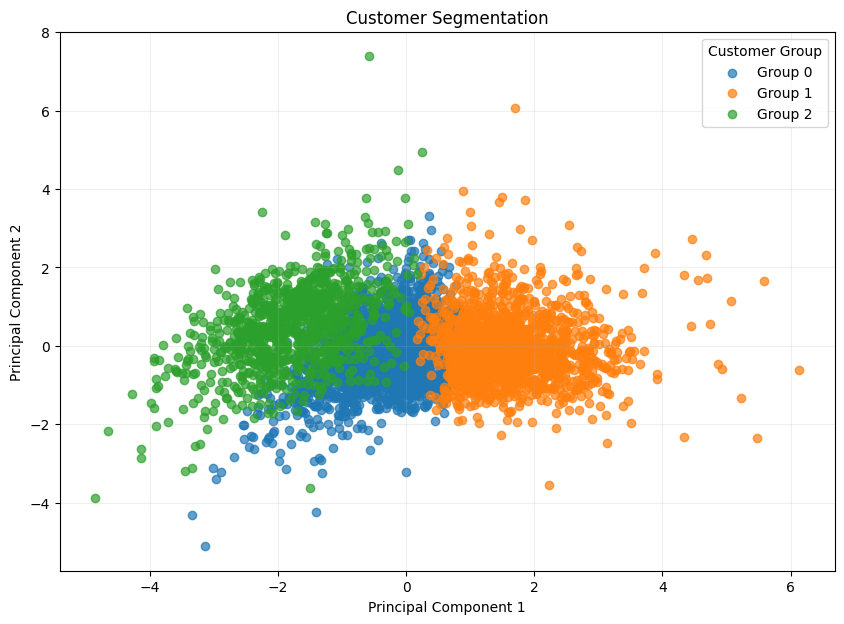

In [132]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

## RFM Baseline

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

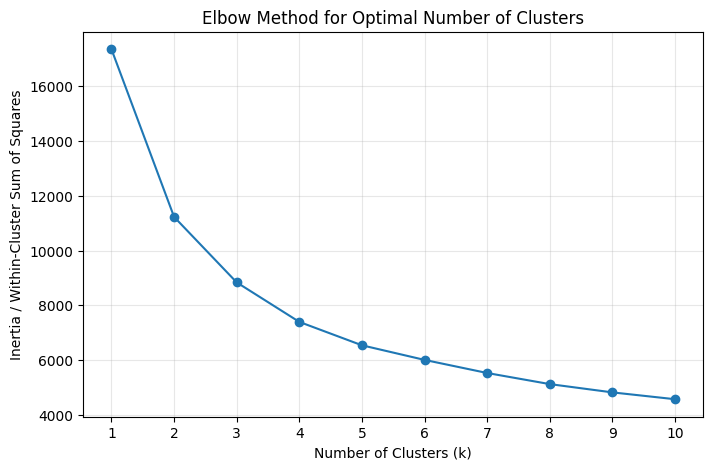

In [133]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [134]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


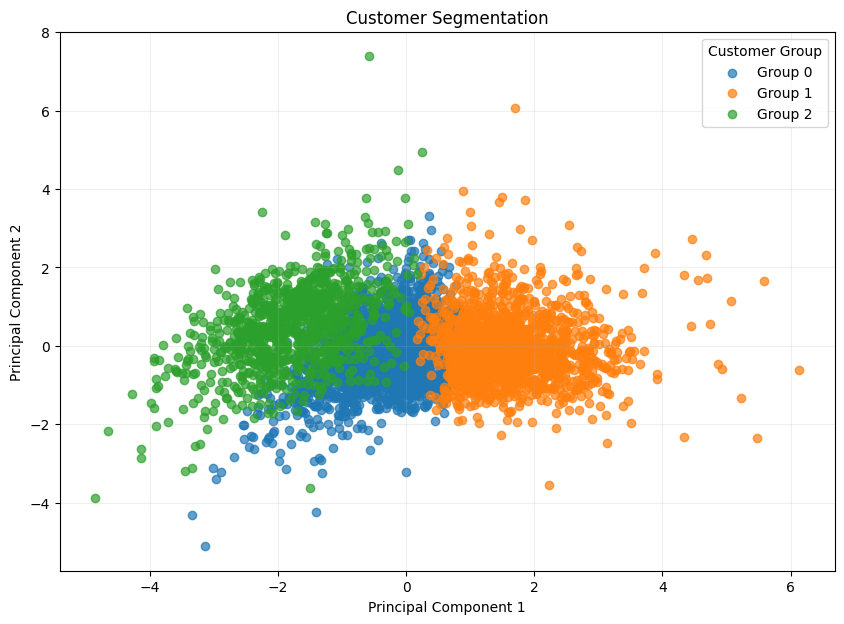

In [135]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [136]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

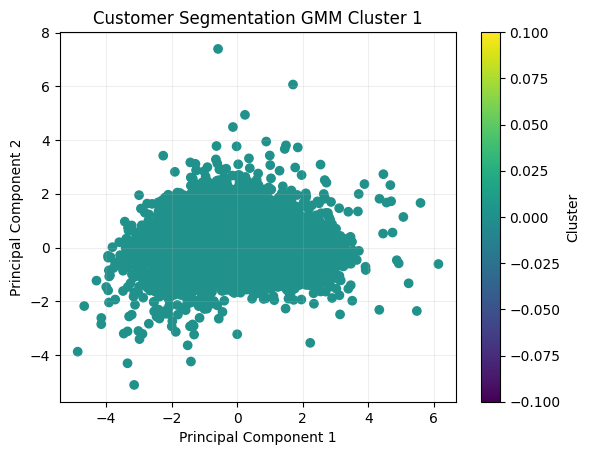

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

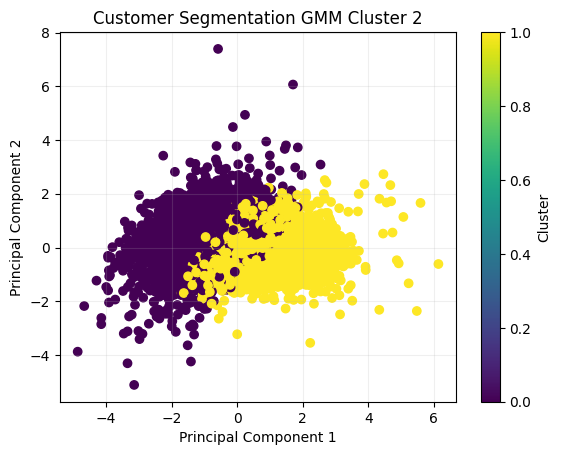

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

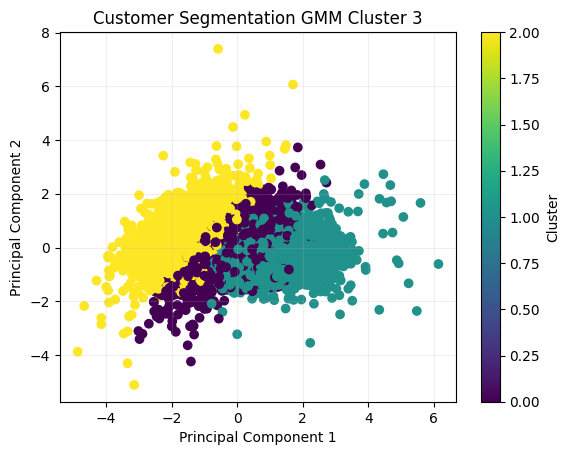

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

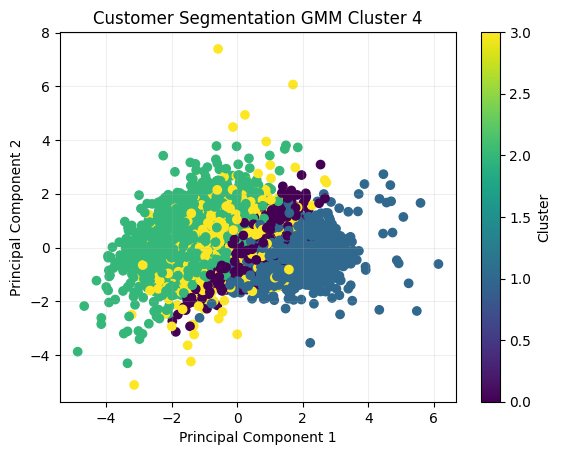

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

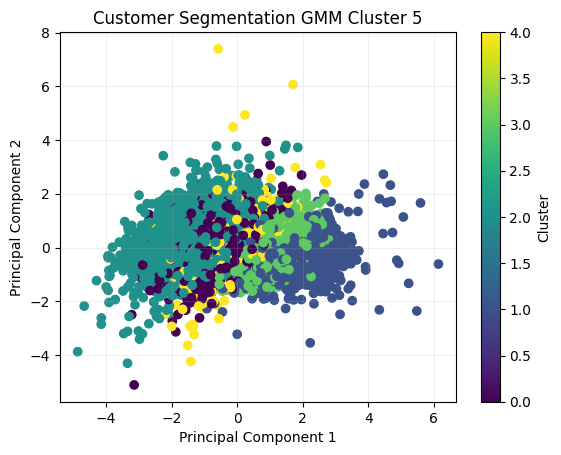

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

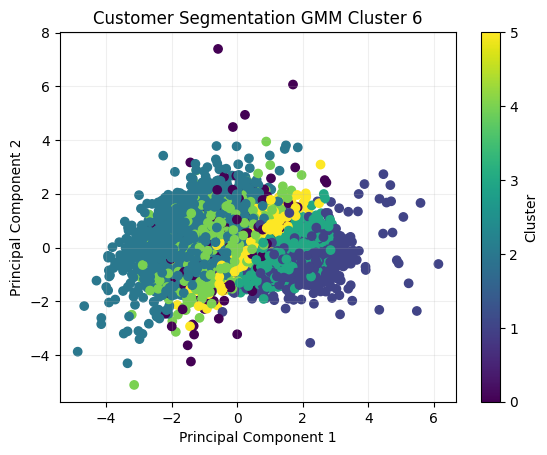

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

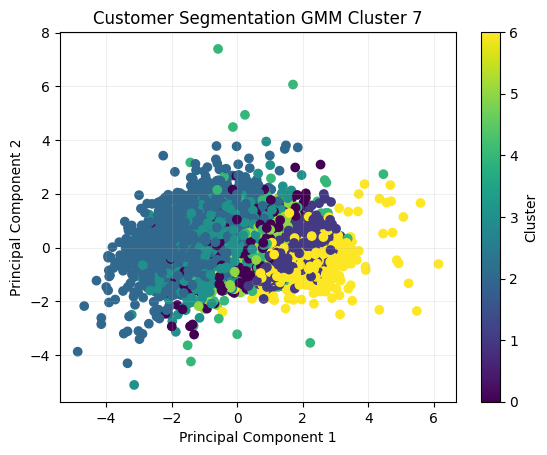

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

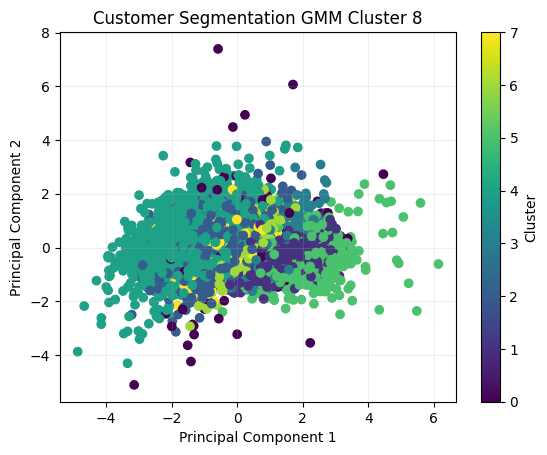

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

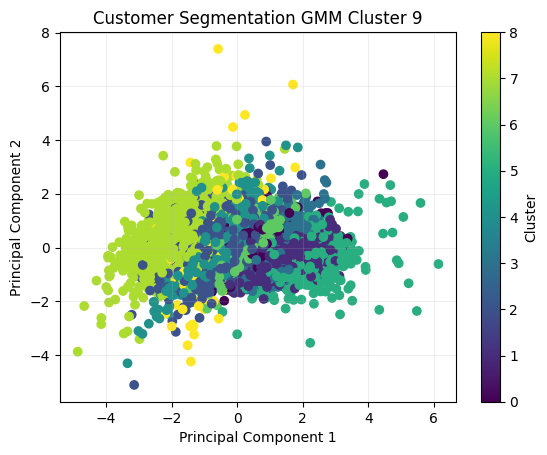

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

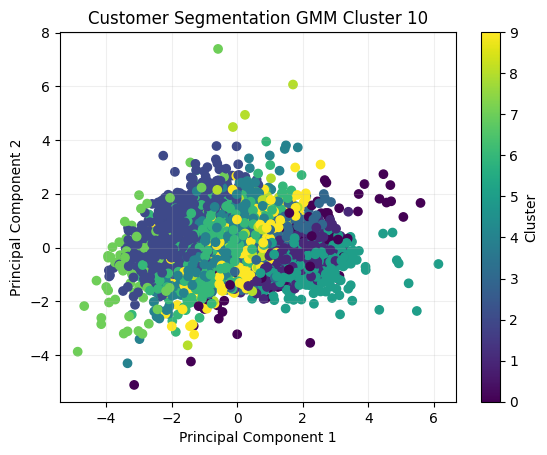

In [137]:
from sklearn.mixture import GaussianMixture
result = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        covariance_type='full'
    )
    
    labels = gmm.fit_predict(X_scaled)
    
    result.append({"K-val": k, "AIC": gmm.aic(X_scaled), "BIC": gmm.bic(X_scaled), "Log-likelihood": gmm.score(X_scaled)})
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [138]:
result

[{'K-val': 1,
  'AIC': np.float64(45069.42592739552),
  'BIC': np.float64(45158.67828907493),
  'Log-likelihood': np.float64(-5.191496764337888)},
 {'K-val': 2,
  'AIC': np.float64(40075.1191467551),
  'BIC': np.float64(40259.99903880532),
  'Log-likelihood': np.float64(-4.612392709400081)},
 {'K-val': 3,
  'AIC': np.float64(38951.34035734798),
  'BIC': np.float64(39231.847779769),
  'Log-likelihood': np.float64(-4.4794076022761615)},
 {'K-val': 4,
  'AIC': np.float64(22572.996741123352),
  'BIC': np.float64(22949.131693915173),
  'Log-likelihood': np.float64(-2.588173898239206)},
 {'K-val': 5,
  'AIC': np.float64(14110.310072067932),
  'BIC': np.float64(14582.072555230558),
  'Log-likelihood': np.float64(-1.609302682349923)},
 {'K-val': 6,
  'AIC': np.float64(13681.540036352679),
  'BIC': np.float64(14248.930049886105),
  'Log-likelihood': np.float64(-1.5564246238304147)},
 {'K-val': 7,
  'AIC': np.float64(8982.723170073972),
  'BIC': np.float64(9645.7407139782),
  'Log-likelihood': n

In [139]:
# reference: https://www.geeksforgeeks.org/data-analysis/rfm-analysis-analysis-using-python/

rfm_df = customer_df[
    ["CustomerID", "recency", "frequency", "monetary"]
].copy()


rfm_df["R_rank"] = rfm_df["recency"].rank(ascending=False)
rfm_df["F_rank"] = rfm_df["frequency"].rank(ascending=True)
rfm_df["M_rank"] = rfm_df["monetary"].rank(ascending=True)

rfm_df["R_rank_norm"] = (
    rfm_df["R_rank"] / rfm_df["R_rank"].max()
) * 100

rfm_df["F_rank_norm"] = (
    rfm_df["F_rank"] / rfm_df["F_rank"].max()
) * 100

rfm_df["M_rank_norm"] = (
    rfm_df["M_rank"] / rfm_df["M_rank"].max()
) * 100

rfm_df["RFM_score"] = (
    0.15 * rfm_df["R_rank_norm"]
    + 0.28 * rfm_df["F_rank_norm"]
    + 0.57 * rfm_df["M_rank_norm"]
)

rfm_df["RFM_score"] *= 0.05

rfm_df["RFM_score"] = rfm_df["RFM_score"].round(2)

In [140]:
rfm_feature = ["R_rank_norm", "F_rank_norm", "M_rank_norm"]

In [141]:
scaler = StandardScaler()
X = rfm_df[rfm_feature]
X_scaled = scaler.fit_transform(X)

X_scaled.shape

(4338, 3)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

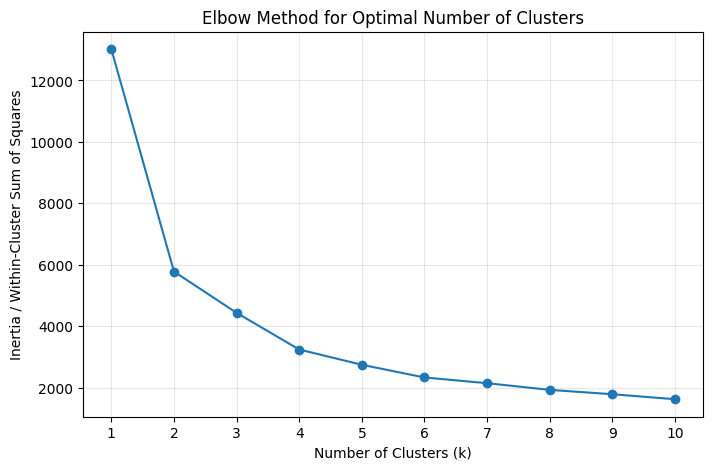

In [142]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [143]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init="auto"
)

rfm_df["cluster"] = kmeans.fit_predict(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


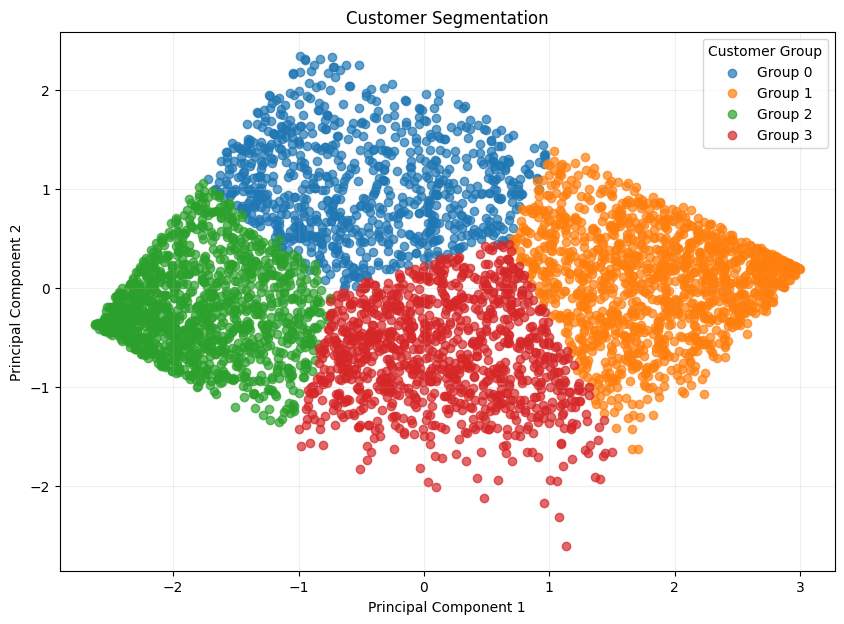

In [144]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

rfm_df["PC1"] = X_pca[:, 0]
rfm_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(rfm_df["cluster"].unique()):
    subset = rfm_df[
        rfm_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [145]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: invalid value encountered in matmul
  X_transformed = X @ self.components_.T


/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

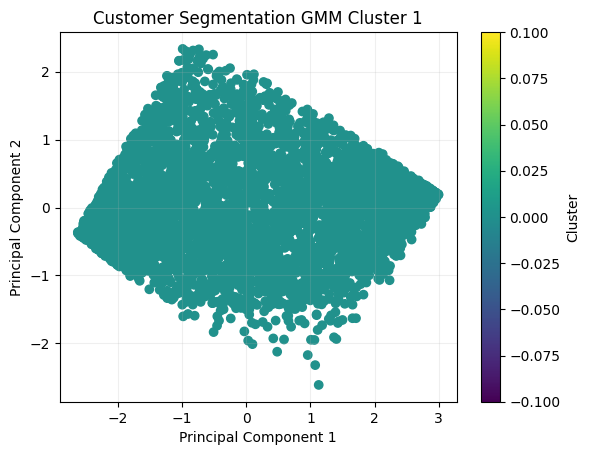

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

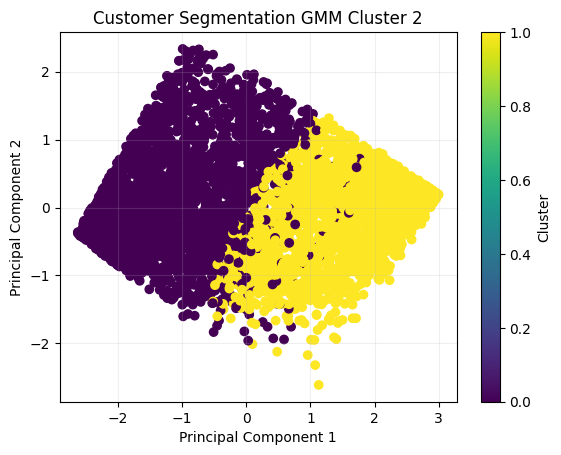

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

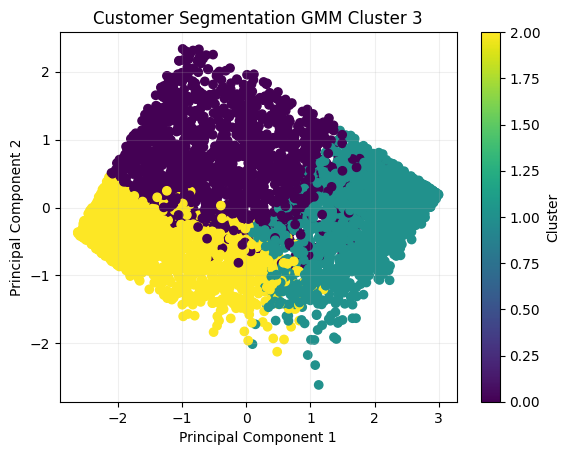

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

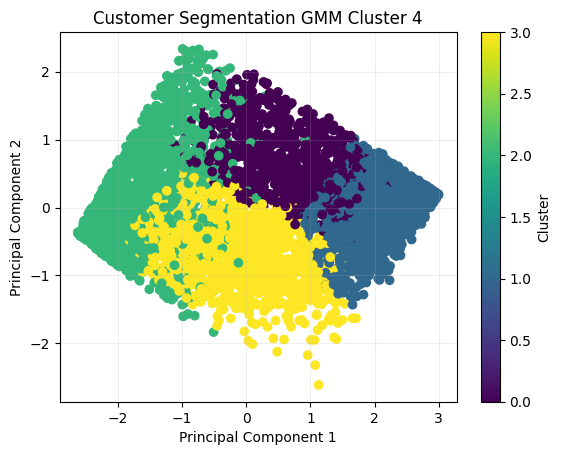

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

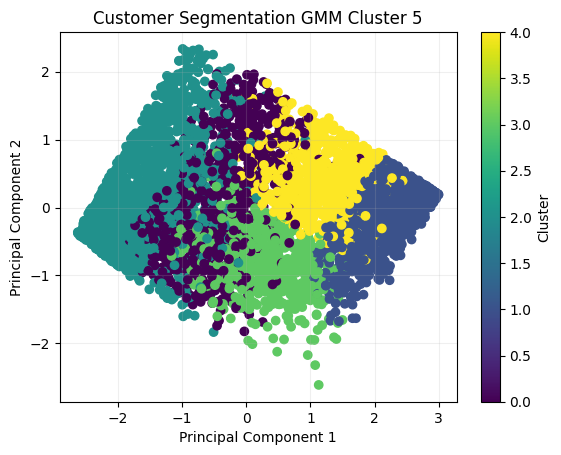

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

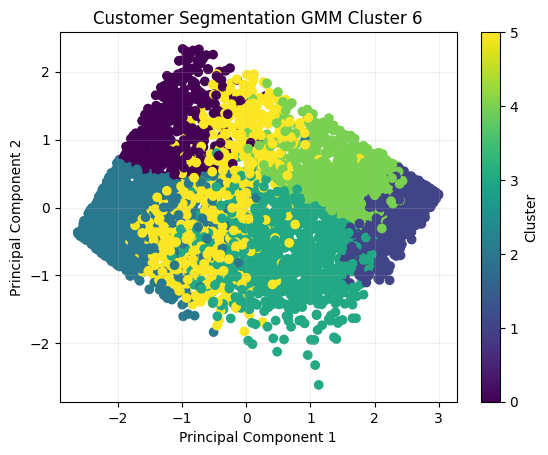

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

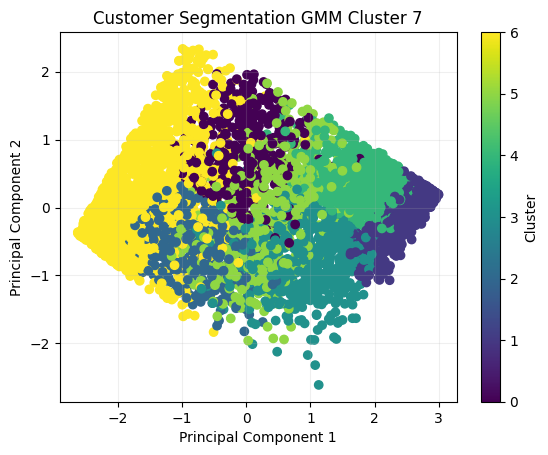

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

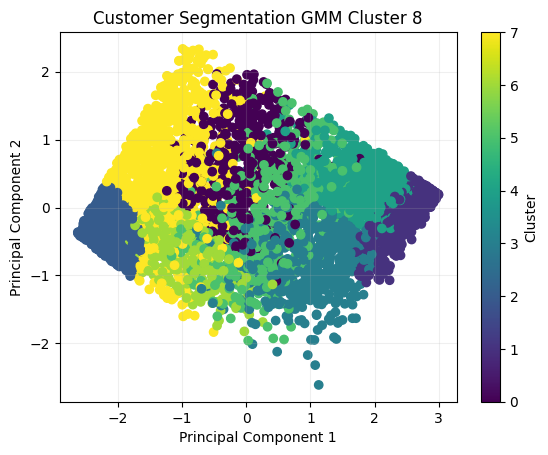

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

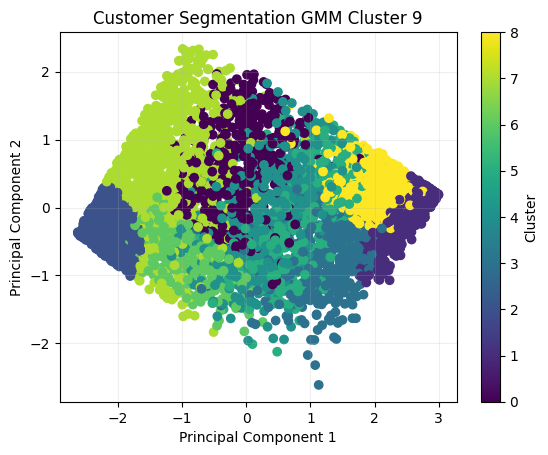

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/

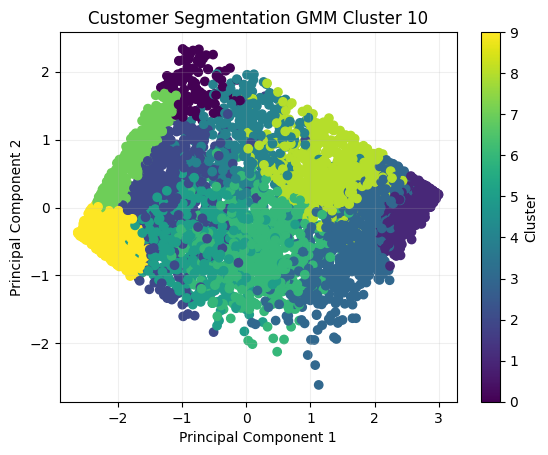

In [146]:
from sklearn.mixture import GaussianMixture
result = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        covariance_type='full'
    )
    
    labels = gmm.fit_predict(X_scaled)
    
    result.append({"K-val": k, "AIC": gmm.aic(X_scaled), "BIC": gmm.bic(X_scaled), "Log-likelihood": gmm.score(X_scaled)})
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [147]:
result

[{'K-val': 1,
  'AIC': np.float64(30714.45099371004),
  'BIC': np.float64(30771.827511932523),
  'Log-likelihood': np.float64(-3.538087943027898)},
 {'K-val': 2,
  'AIC': np.float64(29276.902584934047),
  'BIC': np.float64(29398.030790070396),
  'Log-likelihood': np.float64(-3.370090201121951)},
 {'K-val': 3,
  'AIC': np.float64(28531.415137620148),
  'BIC': np.float64(28716.295029670368),
  'Log-likelihood': np.float64(-3.281859743847412)},
 {'K-val': 4,
  'AIC': np.float64(10251.764162569887),
  'BIC': np.float64(10500.395741533974),
  'Log-likelihood': np.float64(-1.1726330293418497)},
 {'K-val': 5,
  'AIC': np.float64(815.2457874105255),
  'BIC': np.float64(1127.6290532884798),
  'Log-likelihood': np.float64(-0.08267009997816108)},
 {'K-val': 6,
  'AIC': np.float64(446.45559368448784),
  'BIC': np.float64(822.5905464763102),
  'Log-likelihood': np.float64(-0.03785795224579159)},
 {'K-val': 7,
  'AIC': np.float64(-4704.141322002714),
  'BIC': np.float64(-4264.2546822970235),
  'Log-

In [148]:
rfm_df.sort_values(by='RFM_score', ascending=False)

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2
1879,14911.0,1,201,143711.17,4292.0,4337.0,4334.0,100.000000,99.976948,99.907792,5.00,1,2.996402,0.190390
4201,18102.0,1,60,259657.30,4292.0,4328.0,4337.0,100.000000,99.769479,99.976948,5.00,1,2.993274,0.191274
2176,15311.0,1,91,60632.75,4292.0,4333.0,4325.0,100.000000,99.884740,99.700323,4.99,1,2.990078,0.194507
326,12748.0,1,209,33053.19,4292.0,4338.0,4310.0,100.000000,100.000000,99.354541,4.98,1,2.985449,0.198821
1689,14646.0,2,73,280206.02,4202.5,4331.0,4338.0,97.914725,99.838635,100.000000,4.98,1,2.958806,0.129385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1815,14821.0,367,1,48.80,54.5,747.0,37.0,1.269804,17.219917,0.852928,0.27,2,-2.600610,-0.359455
1650,14589.0,372,1,39.75,33.0,747.0,29.0,0.768872,17.219917,0.668511,0.27,2,-2.613190,-0.371195
1640,14576.0,372,1,35.40,33.0,747.0,20.0,0.768872,17.219917,0.461042,0.26,2,-2.617487,-0.367951
402,12855.0,373,1,38.10,17.0,747.0,25.0,0.396086,17.219917,0.576302,0.26,2,-2.621618,-0.380635


In [149]:
category_range = rfm_df.groupby('cluster')['RFM_score'].agg(lambda x: x.max() - x.min())
category_range

cluster
0    2.89
1    2.23
2    2.03
3    2.68
Name: RFM_score, dtype: float64

In [150]:
rfm_df['cluster'].value_counts()

cluster
1    1283
2    1207
3    1018
0     830
Name: count, dtype: int64

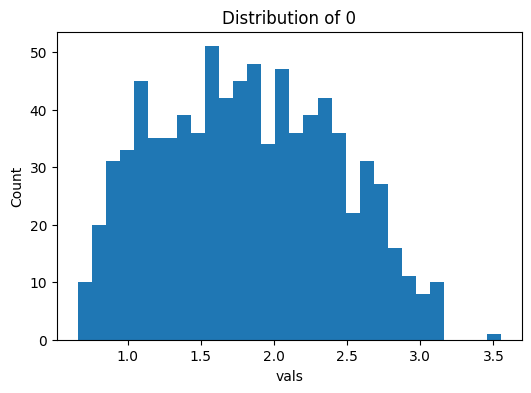

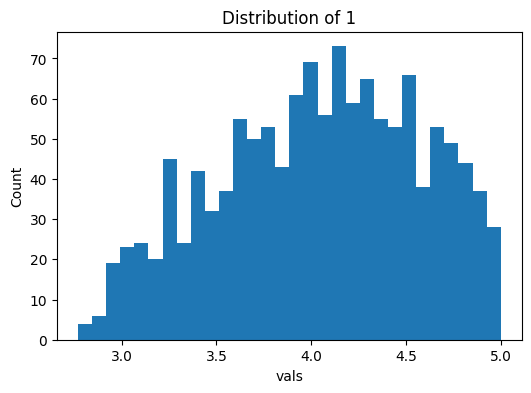

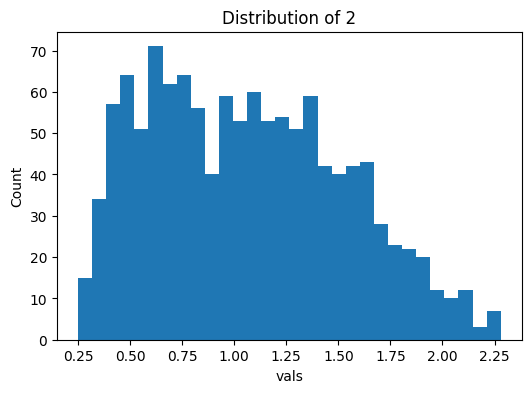

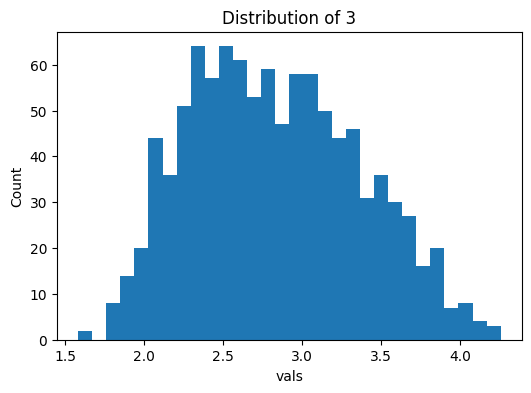

In [151]:
for i in range(0,4):
    cluster_info = rfm_df[rfm_df['cluster'] == i]
    plt.figure(figsize=(6, 4))
    plt.hist(cluster_info[f"RFM_score"], bins=30)
    plt.title(f"Distribution of {i}")
    plt.xlabel("vals")
    plt.ylabel("Count")
    plt.show()

In [152]:
rfm_df

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,3.11,3,-0.507979,-1.833806
1,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,4.56,1,2.484704,0.385319
2,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,3.46,3,0.782264,-0.959285
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,2.97,0,0.237304,0.587438
4,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,1.10,2,-1.953568,-0.674017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,0.68,2,-2.224030,-0.348878
4334,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,0.46,2,-2.240637,0.163919
4335,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,1.64,0,-0.241653,1.744960
4336,18283.0,4,16,2045.53,4015.0,4182.0,3465.0,93.546132,96.403873,79.875519,4.33,1,2.390103,0.349003


In [153]:
import pandas as pd
comparison_data = pd.merge(rfm_df, customer_df, on='CustomerID')
comparison_data

,CustomerID,recency_x,frequency_x,monetary_x,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,...,avg_purchase_val,recency_y,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,cluster_y,PC1_y,PC2_y
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,...,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955,2,-0.580951,7.389867
1,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,...,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406,1,1.953861,0.321743
2,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,...,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936,0,0.294108,0.306387
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,...,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245,1,1.042058,2.158629
4,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,...,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324,2,-1.838842,1.292809
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,...,180.600000,278,5.201806,0.693147,3.828641,2.397895,5.201806,2,-2.220998,0.407221
4334,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,...,80.820000,181,4.404522,0.693147,4.007333,2.079442,4.404522,2,-2.285478,-0.936320
4335,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,...,89.025000,8,5.187665,1.098612,4.644391,2.564949,4.500087,0,-0.831460,-1.655181
4336,18283.0,4,16,2045.53,4015.0,4182.0,3465.0,93.546132,96.403873,79.875519,...,127.845625,4,7.623901,2.833213,7.213768,5.575949,4.858615,1,2.330266,-1.701163


In [156]:
cluster_summary = comparison_data.groupby('cluster_x').agg({
    'recency_x': 'mean',
    'frequency_x': 'mean',
    'monetary_x': 'mean',
    'total_quantity': 'mean',
    'unique_products': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer_Count'})

In [157]:
display(cluster_summary)

,recency_x,frequency_x,monetary_x,total_quantity,unique_products,Customer_Count
cluster_x,,,,,,
0,26.721687,1.633735,392.874916,248.434940,31.462651,830
1,16.569758,9.717069,5257.320382,3002.063913,123.681995,1283
2,206.879039,1.169014,288.728957,169.880696,19.384424,1207
3,106.367387,3.239686,1441.537144,873.386051,57.560904,1018


In [158]:
print(cluster_summary.to_string())

            recency_x  frequency_x   monetary_x  total_quantity  unique_products  Customer_Count
cluster_x                                                                                       
0           26.721687     1.633735   392.874916      248.434940        31.462651             830
1           16.569758     9.717069  5257.320382     3002.063913       123.681995            1283
2          206.879039     1.169014   288.728957      169.880696        19.384424            1207
3          106.367387     3.239686  1441.537144      873.386051        57.560904            1018


----

In [159]:
customer_df.head()

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,cluster,PC1,PC2
0,12346.0,77183.60,1,74215,1,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955,2,-0.580951,7.389867
1,12347.0,4310.00,7,2458,103,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406,1,1.953861,0.321743
2,12348.0,1797.24,4,2341,22,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936,0,0.294108,0.306387
3,12349.0,1757.55,1,631,73,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245,1,1.042058,2.158629
4,12350.0,334.40,1,197,17,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324,2,-1.838842,1.292809


In [160]:
customer_descriptions = (
    df.groupby("CustomerID")["Description"]
      .agg(
          lambda descriptions: " ".join(
              descriptions.dropna().astype(str)
          )
      )
      .reset_index(name="description_text")
)

In [161]:
rfm_text_df = (
    rfm_df[
        ["CustomerID", "recency", "frequency", "monetary"]
    ]
    .merge(
        customer_descriptions,
        on="CustomerID",
        how="left"
    )
)

rfm_text_df["description_text"] = (
    rfm_text_df["description_text"].fillna("")
)

rfm_text_df.head()

,CustomerID,recency,frequency,monetary,description_text
0,12346.0,326,1,77183.60,MEDIUM CERAMIC TOP STORAGE JAR
1,12347.0,2,7,4310.00,BLACK CANDELABRA T-LIGHT HOLDER AIRLINE BAG VI...
2,12348.0,75,4,1797.24,72 SWEETHEART FAIRY CAKE CASES 60 CAKE CASES D...
3,12349.0,19,1,1757.55,PARISIENNE CURIO CABINET SWEETHEART WALL TIDY ...
4,12350.0,310,1,334.40,CHOCOLATE THIS WAY METAL SIGN METAL SIGN NEIGH...


In [162]:
rfm_features = [
    "recency",
    "frequency",
    "monetary"
]

X_rfm = np.log1p(
    rfm_text_df[rfm_features].clip(lower=0)
)

scaler = StandardScaler()
X_rfm_scaled = scaler.fit_transform(X_rfm)


X_rfm_scaled = X_rfm_scaled / np.sqrt(
    X_rfm_scaled.shape[1]
)

In [163]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [164]:
tfidf = TfidfVectorizer(
    stop_words="english",
    lowercase=True,
    min_df=2,
    max_features=1000,
    sublinear_tf=True
)

X_text = tfidf.fit_transform(
    rfm_text_df["description_text"]
)

In [165]:
from scipy.sparse import csr_matrix, hstack
TEXT_WEIGHT = 0.9

X_combined = hstack(
    [
        csr_matrix(X_rfm_scaled),
        TEXT_WEIGHT * X_text
    ],
    format="csr"
)

X_combined.shape

(4338, 1003)

In [166]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

rfm_text_df["cluster"] = kmeans.fit_predict(
    X_combined
)

rfm_text_df.head()

/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: divide by zero encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: overflow encountered in matmul
  current_pot = closest_dist_sq @ sample_weight
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/cluster/_kmeans.py:237: RuntimeWarning: invalid value encountered in matmul
  current_pot = closest_dist_sq @ sample_weight


,CustomerID,recency,frequency,monetary,description_text,cluster
0,12346.0,326,1,77183.60,MEDIUM CERAMIC TOP STORAGE JAR,3
1,12347.0,2,7,4310.00,BLACK CANDELABRA T-LIGHT HOLDER AIRLINE BAG VI...,1
2,12348.0,75,4,1797.24,72 SWEETHEART FAIRY CAKE CASES 60 CAKE CASES D...,3
3,12349.0,19,1,1757.55,PARISIENNE CURIO CABINET SWEETHEART WALL TIDY ...,0
4,12350.0,310,1,334.40,CHOCOLATE THIS WAY METAL SIGN METAL SIGN NEIGH...,2


/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/sparsefuncs.py:734: RuntimeWarning: divide by zero encountered in matmul
  matvec=lambda x: X @ x - offset @ x,
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/sparsefuncs.py:734: RuntimeWarning: overflow encountered in matmul
  matvec=lambda x: X @ x - offset @ x,
/Users/sanyas/Desktop/georgia_tech/CDA/cda-work-arm/lib/python3.9/site-packages/sklearn/utils/sparsefuncs.py:734: RuntimeWarning: invalid value encountered in matmul
  matvec=lambda x: X @ x - offset @ x,


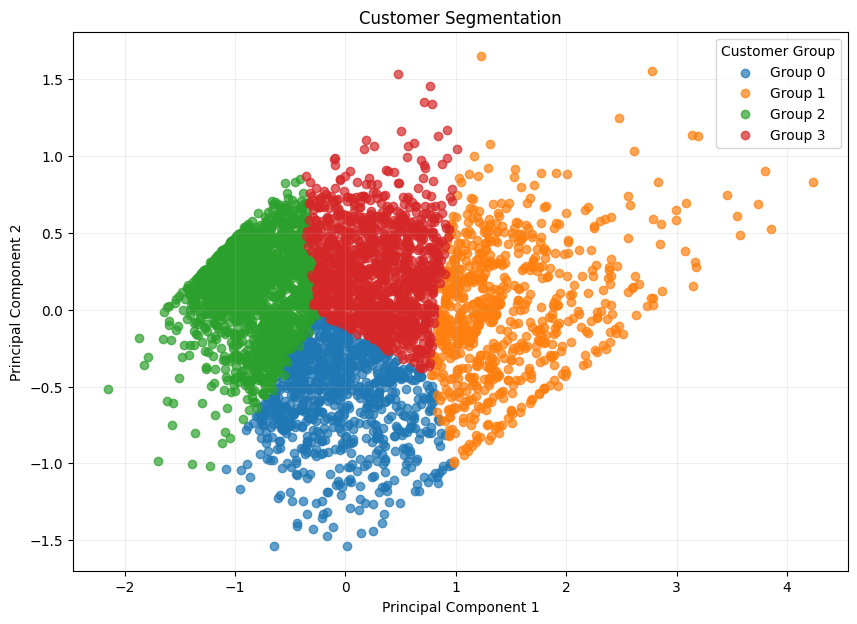

In [167]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_combined)

rfm_text_df["PC1"] = X_pca[:, 0]
rfm_text_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(rfm_text_df["cluster"].unique()):
    subset = rfm_text_df[
        rfm_text_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [168]:
cluster_summary_rfm = (
    rfm_text_df
    .groupby("cluster")
    .agg(
        customers=("CustomerID", "count"),
        recency=("recency", "median"),
        frequency=("frequency", "median"),
        monetary=("monetary", "median")
    )
    .round(2)
)

cluster_summary_rfm 

,customers,recency,frequency,monetary
cluster,,,,
0,866,18.0,2.0,460.92
1,718,8.0,10.0,3715.44
2,1585,179.0,1.0,296.64
3,1169,56.0,4.0,1344.78


In [169]:
terms = np.array(tfidf.get_feature_names_out())

for cluster in sorted(rfm_text_df["cluster"].unique()):
    mask = rfm_text_df["cluster"].eq(cluster).to_numpy()

    average_tfidf = np.asarray(
        X_text[mask].mean(axis=0)
    ).ravel()

    top_terms = terms[
        average_tfidf.argsort()[-10:][::-1]
    ]

    print(
        f"Cluster {cluster}:",
        ", ".join(top_terms)
    )

Cluster 0: christmas, set, heart, vintage, red, bag, retrospot, light, white, box
Cluster 1: bag, set, red, retrospot, vintage, design, christmas, heart, pink, lunch
Cluster 2: set, heart, red, retrospot, bag, design, pink, vintage, hanging, white
Cluster 3: set, bag, red, retrospot, heart, vintage, design, pink, christmas, cake


------

In [170]:
from sklearn.ensemble import IsolationForest
X = rfm_df[['recency', 'frequency', 'monetary']]
Isolation = IsolationForest(contamination=0.2, random_state=42)
rfm_df['anomaly'] = Isolation.fit_predict(X)

In [171]:
analomy = rfm_df[rfm_df['anomaly'] == -1]

In [172]:
non_analomy = rfm_df[rfm_df['anomaly'] == 1]

In [173]:
comparison_data_analomy = pd.merge(analomy, customer_df, on='CustomerID')
comparison_data_analomy

,CustomerID,recency_x,frequency_x,monetary_x,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,...,avg_purchase_val,recency_y,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,cluster_y,PC1_y,PC2_y
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,...,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955,2,-0.580951,7.389867
1,12354.0,232,1,1079.40,603.0,747.0,2785.0,14.049394,17.219917,64.200092,...,1079.400000,232,6.985087,0.693147,6.274762,4.077537,6.985087,2,-0.316298,2.441334
2,12357.0,33,1,6207.67,2587.5,747.0,4137.0,60.286580,17.219917,95.366528,...,6207.670000,33,8.733702,0.693147,7.904335,4.882802,8.733702,1,1.850134,3.724950
3,12359.0,58,4,6310.03,2013.0,3030.5,4144.0,46.901212,69.859382,95.527893,...,1577.507500,58,8.750054,1.609438,7.383989,5.370638,7.364235,1,2.107898,1.906344
4,12362.0,3,10,5226.23,4115.0,3974.5,4084.0,95.876048,91.620562,94.144767,...,522.623000,3,8.561637,2.397895,7.709757,5.308268,6.260772,1,2.479279,0.067726
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
863,18241.0,10,17,2073.09,3653.0,4196.5,3479.0,85.111836,96.738128,80.198248,...,121.946471,10,7.637278,2.890372,6.958448,4.110874,4.811749,1,1.565578,-1.903793
864,18251.0,87,1,4314.72,1490.0,747.0,4005.0,34.715750,17.219917,92.323651,...,4314.720000,87,8.370019,0.693147,8.965079,2.833213,8.370019,0,0.361261,3.318478
865,18260.0,173,6,2628.35,908.0,3552.5,3685.0,21.155638,81.892577,84.946980,...,438.058333,173,7.874492,1.945910,7.297091,4.465908,6.084632,1,0.779559,0.665596
866,18269.0,366,1,168.60,64.0,747.0,507.0,1.491146,17.219917,11.687414,...,168.600000,366,5.133443,0.693147,4.343805,2.079442,5.133443,2,-2.838530,0.654073


In [174]:
comparison_data_non_analomy = pd.merge(non_analomy, customer_df, on='CustomerID')
comparison_data_non_analomy

,CustomerID,recency_x,frequency_x,monetary_x,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,...,avg_purchase_val,recency_y,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,cluster_y,PC1_y,PC2_y
0,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,...,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406,1,1.953861,0.321743
1,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,...,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936,0,0.294108,0.306387
2,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,...,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245,1,1.042058,2.158629
3,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,...,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324,2,-1.838842,1.292809
4,12352.0,36,8,2506.04,2517.5,3830.5,3640.0,58.655638,88.301060,83.909636,...,313.255000,36,7.826858,2.197225,6.285998,4.094345,5.750205,1,1.294530,-0.421895
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3465,18278.0,74,1,173.90,1678.5,747.0,535.0,39.107642,17.219917,12.332872,...,173.900000,74,5.164214,0.693147,4.204693,2.302585,5.164214,0,-1.311834,-0.475008
3466,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,...,180.600000,278,5.201806,0.693147,3.828641,2.397895,5.201806,2,-2.220998,0.407221
3467,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,...,80.820000,181,4.404522,0.693147,4.007333,2.079442,4.404522,2,-2.285478,-0.936320
3468,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,...,89.025000,8,5.187665,1.098612,4.644391,2.564949,4.500087,0,-0.831460,-1.655181


In [178]:
cluster_summary_analomy = comparison_data_analomy.groupby('cluster_x').agg({
    'recency_x': 'mean',
    'frequency_x': 'mean',
    'monetary_x': 'mean',
    'total_quantity': 'mean',
    'unique_products': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer_Count'})

In [179]:
cluster_summary_non_analomy = comparison_data_non_analomy.groupby('cluster_x').agg({
      'recency_x': 'mean',
    'frequency_x': 'mean',
    'monetary_x': 'mean',
    'total_quantity': 'mean',
    'unique_products': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer_Count'})

In [180]:
cluster_summary_non_analomy

,recency_x,frequency_x,monetary_x,total_quantity,unique_products,Customer_Count
cluster_x,,,,,,
0,26.750302,1.634499,388.691411,247.041013,31.499397,829
1,16.653631,5.801117,1948.469598,1194.283799,97.176536,895
2,173.721398,1.145127,273.526643,167.243644,18.579449,944
3,83.733167,2.992519,1065.309728,657.613466,54.894015,802


In [181]:
cluster_summary_analomy

,recency_x,frequency_x,monetary_x,total_quantity,unique_products,Customer_Count
cluster_x,,,,,,
0,3.000000,1.000000,3861.000000,1404.000000,1.000000,1
1,16.376289,18.750000,12889.849897,7172.072165,184.822165,388
2,325.893536,1.254753,343.295437,179.346008,22.273764,263
3,190.407407,4.157407,2838.455606,1674.541667,67.462963,216


In [182]:
cluster_summary

,recency_x,frequency_x,monetary_x,total_quantity,unique_products,Customer_Count
cluster_x,,,,,,
0,26.721687,1.633735,392.874916,248.434940,31.462651,830
1,16.569758,9.717069,5257.320382,3002.063913,123.681995,1283
2,206.879039,1.169014,288.728957,169.880696,19.384424,1207
3,106.367387,3.239686,1441.537144,873.386051,57.560904,1018


In [183]:
customer_df.head()

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,cluster,PC1,PC2
0,12346.0,77183.60,1,74215,1,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955,2,-0.580951,7.389867
1,12347.0,4310.00,7,2458,103,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406,1,1.953861,0.321743
2,12348.0,1797.24,4,2341,22,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936,0,0.294108,0.306387
3,12349.0,1757.55,1,631,73,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245,1,1.042058,2.158629
4,12350.0,334.40,1,197,17,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324,2,-1.838842,1.292809


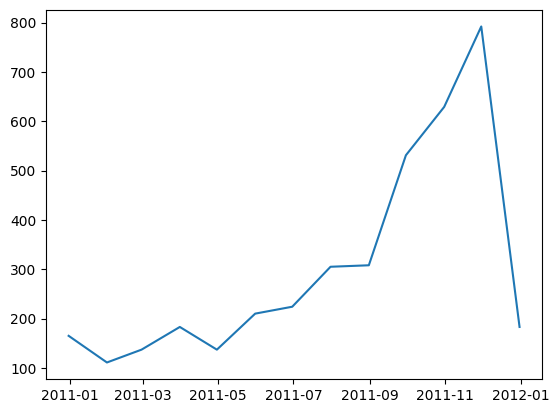

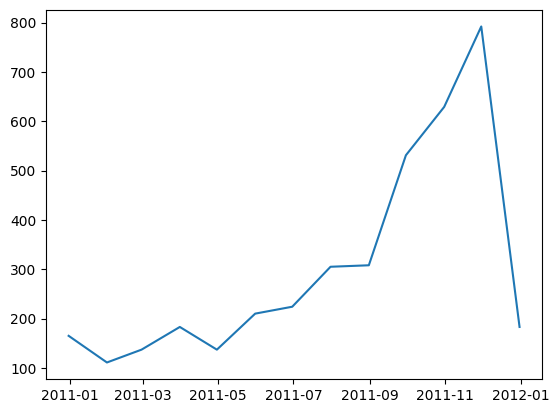

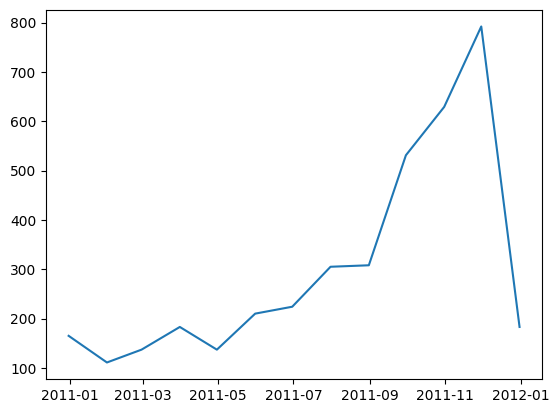

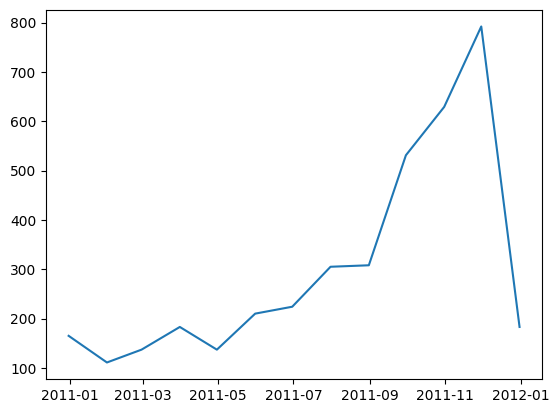

In [193]:
for i in range(1, 5):
    cluster0_id = customer_df[customer_df['cluster'] == 0]
    custid = list(cluster0_id['CustomerID'].unique())
    df0 = df[df['CustomerID'].isin(custid)]
    
    freq = df0.set_index("InvoiceDate").resample('ME')['InvoiceNo'].nunique()
    plt.plot(freq.index, freq.values)
    plt.show()

In [201]:
from collections import Counter
import re
for i in range(1, 5):
    cluster0_id = customer_df[customer_df['cluster'] == 0]
    custid = list(cluster0_id['CustomerID'].unique())
    df0 = df[df['CustomerID'].isin(custid)]

    text = " ".join(df0['Description'].dropna()).lower()

    words = re.findall(r'\b\w+\b', text)


    stop_words = {'is', 'for', 'with', 'and', 'i', 'the', 'a', 'to', 'in', 'set', 'of', 'heart', 'vintage', 'christmas'}
    filtered_words = [w for w in words if w not in stop_words and len(w) > 3]

    print(Counter(filtered_words).most_common(15))
    

[('retrospot', 3501), ('design', 3086), ('pink', 2800), ('cake', 2538), ('light', 2474), ('white', 2422), ('holder', 2150), ('hanging', 2067), ('metal', 2049), ('blue', 1946), ('pack', 1853), ('wooden', 1840), ('jumbo', 1785), ('glass', 1742), ('paper', 1702)]
[('retrospot', 3501), ('design', 3086), ('pink', 2800), ('cake', 2538), ('light', 2474), ('white', 2422), ('holder', 2150), ('hanging', 2067), ('metal', 2049), ('blue', 1946), ('pack', 1853), ('wooden', 1840), ('jumbo', 1785), ('glass', 1742), ('paper', 1702)]
[('retrospot', 3501), ('design', 3086), ('pink', 2800), ('cake', 2538), ('light', 2474), ('white', 2422), ('holder', 2150), ('hanging', 2067), ('metal', 2049), ('blue', 1946), ('pack', 1853), ('wooden', 1840), ('jumbo', 1785), ('glass', 1742), ('paper', 1702)]
[('retrospot', 3501), ('design', 3086), ('pink', 2800), ('cake', 2538), ('light', 2474), ('white', 2422), ('holder', 2150), ('hanging', 2067), ('metal', 2049), ('blue', 1946), ('pack', 1853), ('wooden', 1840), ('jumbo

In [196]:
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,cluster,PC1,PC2
0,12346.0,77183.60,1,74215,1,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955,2,-0.580951,7.389867
1,12347.0,4310.00,7,2458,103,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406,1,1.953861,0.321743
2,12348.0,1797.24,4,2341,22,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936,0,0.294108,0.306387
3,12349.0,1757.55,1,631,73,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245,1,1.042058,2.158629
4,12350.0,334.40,1,197,17,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324,2,-1.838842,1.292809
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,180.600000,278,5.201806,0.693147,3.828641,2.397895,5.201806,2,-2.220998,0.407221
4334,18281.0,80.82,1,54,7,80.820000,181,4.404522,0.693147,4.007333,2.079442,4.404522,2,-2.285478,-0.936320
4335,18282.0,178.05,2,103,12,89.025000,8,5.187665,1.098612,4.644391,2.564949,4.500087,0,-0.831460,-1.655181
4336,18283.0,2045.53,16,1357,263,127.845625,4,7.623901,2.833213,7.213768,5.575949,4.858615,1,2.330266,-1.701163


In [195]:
counts = df.set_index('cluster')['Description'].str.split().explode().groupby(level=0).apply(pd.value_counts)
counts

KeyError: "None of ['cluster'] are in the columns"